In [1]:
import xarray as xr
import json
import pandas as pd
import torch
import numpy as np
from scipy.stats import gaussian_kde
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

import os
import sys
sys.path.append('../')
import utils.utils as ut
import importlib

**In the following cell you need to adjust some paths.**

In [2]:
##################
### set domain ###
##################
### Germany ###
# coordinates 
domain="GER"
lat_min = 48
lat_max = 54
lon_min = 6
lon_max = 15

settings_file_path = "../../settings.json"
with open(settings_file_path, 'r') as file:
        settings = json.load(file)
no_epochs=settings['epochs']
standardization="inherent_detrended"



#############
### Truth ###
#############
era5_truth_pre = xr.open_dataset("/work2/fl53wumy-dae_data/fl53wumy-ws_new-1790472002/fl53wumy-fl53wumy-llaae_ws_new-1779067202-1785633601/fl53wumy-llaae_ws_new-1779067202/fl53wumy-dpa_data/fl53wumy-llaae_data_new_22092025-1763346001/fl53wumy-llaae_data_new-1758244802/fl53wumy-llaae_data_new-1748049607/dpa_output/v5_model/working_project/DAE_data_reproduce_results/input_data/E5sf00_1D_2026-06_167_remapped_to_CESM2_anom.nc")
display(era5_truth_pre)

###########
### DAE ###
###########
    
dae_ensemble_fact = f"{settings['current_model']}/dae_ensemble_after_{no_epochs}_epochs/ERA5_{standardization}_ensemble_after_{no_epochs}_epochs/ETH_gen2026_dpa_ens_{no_epochs}_dataset_restored.nc"
dae_eth_fact_path = os.path.join(settings['paths']['output_dir'], dae_ensemble_fact)
dae_eth_fact_pre = xr.open_dataset(dae_eth_fact_path)
#display(dae_eth_fact_pre)

dae_ensemble_cf = f"{settings['current_model']}/dae_ensemble_after_{no_epochs}_epochs/ERA5_{standardization}_ensemble_after_{no_epochs}_epochs/ETH_cf_gen2026_dpa_ens_{no_epochs}_dataset_restored.nc"
dae_eth_cf_path = os.path.join(settings['paths']['output_dir'], dae_ensemble_cf)
dae_eth_cf_pre = xr.open_dataset(dae_eth_cf_path)
#display(dae_eth_cf_pre)

###################
### Climatology ###
###################
era5_clim_pre2 = xr.open_dataset("/work2/fl53wumy-dae_data/fl53wumy-ws_new-1790472002/fl53wumy-fl53wumy-llaae_ws_new-1779067202-1785633601/fl53wumy-llaae_ws_new-1779067202/fl53wumy-dpa_data/fl53wumy-llaae_data_new_22092025-1763346001/fl53wumy-llaae_data_new-1758244802/fl53wumy-llaae_data_new-1748049607/dpa_output/v5_model/working_project/DAE_data_reproduce_results/other_data/E5sf00_1D_T2M_1940-2025_remapped_to_CESM2_no_leap_clim.nc") #E5sf00_1D_T2M_1940-2025_remapped_to_CESM2_no_leap_clim.nc
era5_clim_pre = era5_clim_pre2.assign_coords(lon=((era5_clim_pre2.lon + 180) % 360) - 180).sortby("lon").sel(lat=era5_truth_pre.lat, lon=era5_truth_pre.lon).sel(time=slice("1980-06-02", "1980-06-27"))
era5_clim = era5_clim_pre.assign_coords(time=era5_truth_pre.sel(time=slice("2026-06-02", "2026-06-27")).time)
#display(era5_clim)
#
#display(era5_clim.var167)

# add clims
# truth
ds_test_eth_fact = era5_truth_pre.T2M + era5_clim.var167 - 273.15

# DAE
dae_eth_fact = dae_eth_fact_pre.TREFHT + era5_clim.var167.assign_coords(time=dae_eth_fact_pre.sel(time=slice("2026-06-02", "2026-06-27")).time) - 273.15
dae_eth_cf = dae_eth_cf_pre.TREFHT + era5_clim.var167.assign_coords(time=dae_eth_cf_pre.sel(time=slice("2026-06-02", "2026-06-27")).time) - 273.15


# compute domain averages

############
### Test ###
############
#era5_truth_ger_pre = ut.get_ger_1d_data(era5_truth, 
#                                     lat_min = lat_min,
#                                     lat_max = lat_max,
#                                     lon_min = lon_min,
#                                     lon_max = lon_max)

#era5_truth_ger = era5_truth_ger_pre.assign_coords(time=dae_eth_fact.time)

###########
### DAE ###
###########
#trefht_le_fact_ger = ut.get_ger_1d_data(dae_eth_fact_abs, 
#                                     lat_min = lat_min,
#                                     lat_max = lat_max,
#                                     lon_min = lon_min,
#                                     lon_max = lon_max)

#trefht_le_cf_ger = ut.get_ger_1d_data(dae_eth_cf_abs, 
#                                     lat_min = lat_min,
#                                     lat_max = lat_max,
#                                     lon_min = lon_min,
#                                     lon_max = lon_max)

#era5_truth_ger.plot()
#fact_dae_median.plot()
#trefht_le_cf_ger_median.plot()

fact_dae_mean = dae_eth_fact.median(dim="ensemble_member")
cf_dae_mean = dae_eth_cf.median(dim="ensemble_member")



<xarray.Dataset> Size: 25kB
Dimensions:    (time: 6, bnds: 2, lon: 32, lat: 32)
Coordinates:
  * time       (time) datetime64[ns] 48B 2026-06-02T23:30:00 ... 2026-06-27T1...
  * lon        (lon) float64 256B -11.25 -10.0 -8.75 -7.5 ... 25.0 26.25 27.5
  * lat        (lat) float64 256B 34.4 35.34 36.28 37.23 ... 61.73 62.67 63.61
Dimensions without coordinates: bnds
Data variables:
    time_bnds  (time, bnds) datetime64[ns] 96B ...
    T2M        (time, lat, lon) float32 25kB ...
Attributes:
    CDI:          Climate Data Interface version 2.2.4 (https://mpimet.mpg.de...
    Conventions:  CF-1.6
    institution:  European Centre for Medium-Range Weather Forecasts
    history:      Mon Oct 05 23:46:11 2026: cdo -selvar,T2M -sellonlatbox,-12...
    CDO:          Climate Data Operators version 2.2.2 (https://mpimet.mpg.de...

In [3]:
dae_eth_fact

<xarray.DataArray (ensemble_member: 1000, time: 6, lat: 32, lon: 32)> Size: 25MB
array([[[[       nan,        nan,        nan, ...,        nan,
                 nan,        nan],
         [       nan,        nan,        nan, ..., 21.529083 ,
                 nan,        nan],
         [       nan,        nan,        nan, ...,        nan,
                 nan,        nan],
         ...,
         [       nan,        nan,        nan, ..., 17.510712 ,
          17.551483 , 18.078766 ],
         [       nan,        nan,        nan, ..., 18.46222  ,
          18.00299  , 17.685303 ],
         [       nan,        nan,        nan, ..., 18.57608  ,
          18.823364 , 18.805054 ]],

        [[       nan,        nan,        nan, ...,        nan,
                 nan,        nan],
         [       nan,        nan,        nan, ..., 22.932556 ,
                 nan,        nan],
         [       nan,        nan,        nan, ...,        nan,
                 nan,        nan],
...
          13.736206 , 14.274811 ],
         [       nan,        nan,        nan, ..., 12.540253 ,
          13.327057 , 13.728088 ],
         [       nan,        nan,        nan, ..., 12.549011 ,
          13.108185 , 13.443665 ]],

        [[       nan,        nan,        nan, ...,        nan,
                 nan,        nan],
         [       nan,        nan,        nan, ..., 27.384857 ,
                 nan,        nan],
         [       nan,        nan,        nan, ...,        nan,
                 nan,        nan],
         ...,
         [       nan,        nan,        nan, ..., 17.990356 ,
          17.606598 , 17.399536 ],
         [       nan,        nan,        nan, ..., 18.103546 ,
          17.960815 , 17.179565 ],
         [       nan,        nan,        nan, ..., 18.190704 ,
          17.82367  , 17.276337 ]]]],
      shape=(1000, 6, 32, 32), dtype=float32)
Coordinates:
  * ensemble_member  (ensemble_member) int64 8kB 1 2 3 4 5 ... 997 998 999 1000
  * time             (time) object 48B 2026-06-02 00:00:00 ... 2026-06-27 00:...
  * lat              (lat) float64 256B 34.4 35.34 36.28 ... 61.73 62.67 63.61
  * lon              (lon) float64 256B -11.25 -10.0 -8.75 ... 25.0 26.25 27.5

In [2]:
# load true test data
settings_file_path = "../../settings.json"
with open(settings_file_path, 'r') as file:
        settings = json.load(file)
no_epochs=settings['epochs']
#standardization="train_stats"
#standardization="inherent"
#standardization="train_stats_detrended"
standardization="inherent_detrended"


### Factual ###
    
### Load temperature TEST data ###
ds_test_eth_fact_path_dummy = os.path.join(settings['paths']['data'], settings['paths']['dataset_trefht_era5_transient'])
ds_test_eth_fact_pre_dummy = xr.open_dataset(ds_test_eth_fact_path_dummy)

# load CESM2 fact nudged to ERA5
# adjust path to where you saved "ERA5_factual_nudged_europe_10percent_masked_TREFHT_JJA.nc"
#ds_test_eth_fact_pre2 = xr.open_dataset("/work2/fl53wumy-ws_new/fl53wumy-fl53wumy-llaae_ws_new-1779067202-1785633601/fl53wumy-llaae_ws_new-1779067202/fl53wumy-dpa_data/fl53wumy-llaae_data_new_22092025-1763346001/fl53wumy-llaae_data_new-1758244802/fl53wumy-llaae_data_new-1748049607/other_data/ERA5_factual_nudged_europe_10percent_masked_TREFHT_JJA.nc")
ds_test_eth_fact_pre2 = xr.open_dataset(os.path.join(settings['paths']['data'], settings['paths']['dataset_trefht_era5_fact_nudged']))
ds_test_eth_fact_pre = ds_test_eth_fact_pre2.assign_coords(lat=ds_test_eth_fact_pre_dummy.lat, lon=ds_test_eth_fact_pre_dummy.lon)

### load climatology ###
# load climatology
# adjust paths to where you saved "merged_TSA_fact_nudged_1940-2024_clim.nc"
era5_clim_pre = xr.open_dataset(os.path.join(settings['paths']['other_data'], "merged_TSA_fact_nudged_1940-2024_clim.nc")).TSA #E5sf00_1D_T2M_1940-2025_remapped_to_CESM2_no_leap_clim.nc
era5_clim = era5_clim_pre.assign_coords(lon=((era5_clim_pre.lon + 180) % 360) - 180).sortby("lon").sel(lat=ds_test_eth_fact_pre.lat, lon=ds_test_eth_fact_pre.lon).sel(time=slice("1980-06-02", "1980-08-31"))


# add climatology
era5_clim_correct = np.transpose(np.tile(era5_clim.values, (84,1,1)), (0,1,2))
ds_test_eth_fact = ds_test_eth_fact_pre + era5_clim_correct - 273.15
print(ds_test_eth_fact)

# load DAE ensemble
# ADJUST FOLLOWING PATH IF NECESSARY

# current
#dae_ensemble_fact = "_devicecuda100_6_100_100_1001_20_2_50_encoderislearnable_lambda0.5_alpha1.5_bs128_bnisFalse_lr0.0001_pene0/dae_ensemble_after_50_epochs/ERA5_inherent_ensemble_after_50_epochs/ETH_gen_dpa_ens_50_dataset_restored.nc"
dae_ensemble_fact = f"{settings['current_model']}/dae_ensemble_after_{no_epochs}_epochs/ERA5_{standardization}_ensemble_after_{no_epochs}_epochs/ETH_gen2026_dpa_ens_{no_epochs}_dataset_restored.nc"
dae_eth_fact_path = os.path.join(settings['paths']['output_dir'], dae_ensemble_fact)

# old generated ensemble, but good ?
#dae_eth_fact_path="/work2/fl53wumy-llaae_ws_new/fl53wumy-dpa_data/fl53wumy-llaae_data_new_22092025-1763346001/fl53wumy-llaae_data_new-1758244802/fl53wumy-llaae_data_new-1748049607/dpa_output/v5_model/_devicecpu100_6_100_100_1001_100_2_100_encoderislearnable_lambda1.0_alpha1.0_bs128_bnisTrue_lr5e-05_pene0/era5_test_set_reference_period_1950-1980_v5_dpa_train_settings_home_ERA5.json/dpa_ensemble_after_50_epochs/eth_ensemble_after_50_epochs/ETH_gen_dpa_ens_50_dataset_restored.nc"

dae_eth_fact = xr.open_dataset(dae_eth_fact_path) + np.transpose(era5_clim_correct, (0,1,2)) - 273.15
print("dae_eth_fact_path:", dae_eth_fact_path)
dae_eth_fact


### Counterfactual ###

### Load counterfactual temperature TEST data ###
ds_test_eth_cf_path = os.path.join(settings['paths']['data'], settings['paths']['dataset_trefht_era5_nudged'])
ds_test_eth_cf_pre = xr.open_dataset(ds_test_eth_cf_path)

# load climatology
# adjust paths to where you saved "merged_TREFHT_nudged_1940-2015_clim.nc"
era5_nudged_clim_pre = xr.open_dataset(os.path.join(settings['paths']['other_data'], "merged_TREFHT_nudged_1940-2015_clim.nc")).TREFHT
era5_nudged_clim = era5_nudged_clim_pre.assign_coords(lon=((era5_nudged_clim_pre.lon + 180) % 360) - 180).sortby("lon").sel(lat=ds_test_eth_cf_pre.lat, lon=ds_test_eth_cf_pre.lon).sel(time=slice("1980-06-02", "1980-08-31"))
era5_nudged_clim_correct = np.transpose(np.tile(era5_nudged_clim.values, (84,1,1)), (0,1,2))

# add climatology
ds_test_eth_cf = ds_test_eth_cf_pre + era5_nudged_clim_correct - 273.15#.rename({"var167": "TREFHT"})

# load DPA ensemble
# ADJUST FOLLOWING PATH IF NECESSARY

# current

dae_ensemble_cf = f"{settings['current_model']}/dae_ensemble_after_{no_epochs}_epochs/ERA5_{standardization}_ensemble_after_{no_epochs}_epochs/ETH_cf_gen2026_dpa_ens_{no_epochs}_dataset_restored.nc"
dae_eth_cf_path = os.path.join(settings['paths']['output_dir'], dae_ensemble_cf)

#dae_ensemble_cf_2028 = f"{settings['current_model']}/dae_ensemble_after_{no_epochs}_epochs/ERA5_{standardization}_ensemble_after_{no_epochs}_epochs/ETH_cf_era5_2028_gen_dpa_ens_{no_epochs}_dataset_restored.nc"
#dae_eth_cf_path_2028 = os.path.join(settings['paths']['output_dir'], dae_ensemble_cf_2028)

#dae_ensemble_cf_2053 = f"{settings['current_model']}/dae_ensemble_after_{no_epochs}_epochs/ERA5_{standardization}_ensemble_after_{no_epochs}_epochs/ETH_cf_era5_2053_gen_dpa_ens_{no_epochs}_dataset_restored.nc"
#dae_eth_cf_path_2053 = os.path.join(settings['paths']['output_dir'], dae_ensemble_cf_2053)


# old generated ensemble, but good ?
#dae_eth_cf_path="/work2/fl53wumy-llaae_ws_new/fl53wumy-dpa_data/fl53wumy-llaae_data_new_22092025-1763346001/fl53wumy-llaae_data_new-1758244802/fl53wumy-llaae_data_new-1748049607/dpa_output/v5_model/_devicecpu100_6_100_100_1001_100_2_100_encoderislearnable_lambda1.0_alpha1.0_bs128_bnisTrue_lr5e-05_pene0/era5_test_set_reference_period_1950-1980_v5_dpa_train_settings_home_ERA5.json/dpa_ensemble_after_50_epochs/eth_ensemble_after_50_epochs/ETH_cf_gen_dpa_ens_50_dataset_restored.nc"

# need to add factual era5 anomalies as this is what model learns !!!
dae_eth_cf = xr.open_dataset(dae_eth_cf_path) +  np.transpose(era5_clim_correct,(0,1,2)) - 273.15#.rename({"var167": "TREFHT"})
#dae_eth_cf_2028 = xr.open_dataset(dae_eth_cf_path_2028) +  np.transpose(era5_clim.values,(0,1,2)) - 273.15#.rename({"var167": "TREFHT"}) # add only one summer climatology
#dae_eth_cf_2053 = xr.open_dataset(dae_eth_cf_path_2053) +  np.transpose(era5_clim.values,(0,1,2)) - 273.15#.rename({"var167": "TREFHT"}) # add only one summer climatology


# compute domain average temperature
weights = np.cos(np.deg2rad(dae_eth_fact.lat))
dae_eth_ens_spatial_mean = dae_eth_fact.TREFHT.weighted(weights).mean(dim=("lat","lon"))
weights = np.cos(np.deg2rad(dae_eth_cf.lat))
dae_eth_ens_spatial_mean_cf = dae_eth_cf.TREFHT.weighted(weights).mean(dim=("lat","lon"))
#dae_eth_ens_spatial_mean_cf_2028 = dae_eth_cf_2028.TREFHT.weighted(weights).mean(dim=("lat","lon"))
#dae_eth_ens_spatial_mean_cf_2053 = dae_eth_cf_2053.TREFHT.weighted(weights).mean(dim=("lat","lon"))

# compute ensemble 
# MEAN 
#fact_dae_mean = dae_eth_fact.mean(dim="ensemble_member")
#cf_dae_mean = dae_eth_cf.mean(dim="ensemble_member")
#cf_2028_dae_mean = dae_eth_cf_2028.mean(dim="ensemble_member")
#cf_2053_dae_mean = dae_eth_cf_2053.mean(dim="ensemble_member")

# or MEDIAN
fact_dae_mean = dae_eth_fact.median(dim="ensemble_member")
cf_dae_mean = dae_eth_cf.median(dim="ensemble_member")
#cf_2028_dae_mean = dae_eth_cf_2028.median(dim="ensemble_member")
#cf_2053_dae_mean = dae_eth_cf_2053.median(dim="ensemble_member")

##################
### set domain ###
##################
# FRANCE
fr_lat_min = 45
fr_lat_max = 50
fr_lon_min= 0
fr_lon_max= 5

<xarray.Dataset> Size: 7MB
Dimensions:  (time: 1596, lat: 32, lon: 32)
Coordinates:
  * time     (time) object 13kB 1940-06-02 00:00:00 ... 2023-08-31 00:00:00
  * lat      (lat) float64 256B 34.4 35.34 36.28 37.23 ... 61.73 62.67 63.61
  * lon      (lon) float64 256B -11.25 -10.0 -8.75 -7.5 ... 25.0 26.25 27.5
Data variables:
    TSA      (time, lat, lon) float32 7MB nan nan nan nan ... 15.5 15.46 15.59
dae_eth_fact_path: /work2/fl53wumy-dae_data/fl53wumy-ws_new-1790472002/fl53wumy-fl53wumy-llaae_ws_new-1779067202-1785633601/fl53wumy-llaae_ws_new-1779067202/fl53wumy-dpa_data/fl53wumy-llaae_data_new_22092025-1763346001/fl53wumy-llaae_data_new-1758244802/fl53wumy-llaae_data_new-1748049607/dpa_output/v5_model/working_project/DAE_data_reproduce_results/output_data/_devicecpu50_6_100_5_1001_20_2_50_encoderislearnable_lambda1.0_alpha1.5_bs128_bnisFalse_lr0.0001_pene0/dae_ensemble_after_80_epochs/ERA5_inherent_detrended_ensemble_after_80_epochs/ETH_gen_dpa_ens_80_dataset_restored.nc


## Explore ERA5 DAE ensemble

### Heatwave visualization

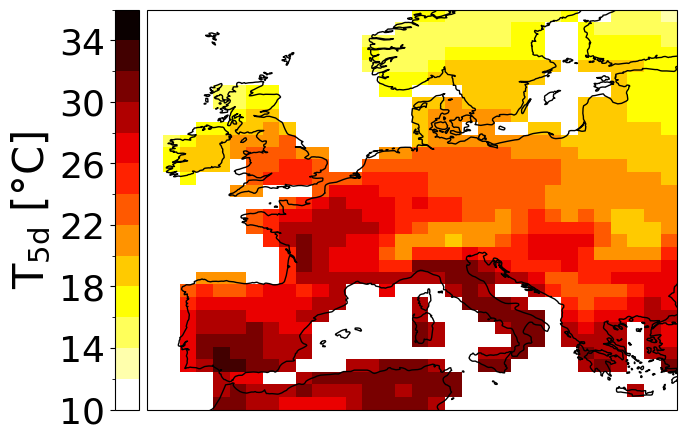

In [4]:
# factual

trefht_hw = fact_dae_mean.TREFHT.sel(time="2003-08-11")

fig = plt.figure(figsize=(8,5))
ax  = fig.add_axes([0.18, 0.1, 0.77, 0.8], projection=ccrs.PlateCarree())
cax = fig.add_axes([0.14, 0.1, 0.02, 0.8])  # same height as map

vmin = 10
vmax = 36
no_levels=14
levels = np.linspace(vmin,vmax,no_levels)

trefht_hw.plot(
    ax=ax,
    transform=ccrs.PlateCarree(),
    cmap=  "hot_r", #"coolwarm",
    levels=levels,
    cbar_ax=cax,
    cbar_kwargs={"label": "T-Anomaly [°C]"}
)

cax.yaxis.set_label_position("left")
cax.yaxis.tick_left()

cbar = cax
cbar_width = 0.03
cbar_gap = 0.01
cbar_tick_label_size = 26
cbar.set_ylabel(r"$\mathrm{T_{5d}}$ [°C]", fontsize=30)
#cbar.set_ylim(20, 36)
cax.tick_params(axis="y", labelsize=cbar_tick_label_size)
#cbar.set_ticks(np.linspace(vmin,vmax,11))
ax_pos = ax.get_position()
cax.set_position([ax_pos.x0 - cbar_gap - cbar_width, ax_pos.y0, cbar_width, ax_pos.height])
ax.coastlines()
ax.set_title("")
#plt.savefig("hw_fact_temperature_map.pdf", bbox_inches='tight')
plt.show()

### ERA5 bias

In [5]:
def weighted_domain_mean(da, lat_min=None, lat_max=None, lon_min=None, lon_max=None):
    """Latitude-weighted spatial mean over a rectangular domain.

    If lat_min/lat_max/lon_min/lon_max are not given, the full domain
    extent of `da` is used.
    """
    if lat_min is None:
        lat_min = float(da["lat"].min())
    if lat_max is None:
        lat_max = float(da["lat"].max())
    if lon_min is None:
        lon_min = float(da["lon"].min())
    if lon_max is None:
        lon_max = float(da["lon"].max())

    da_domain = da.sel(
        lat=slice(lat_min, lat_max),
        lon=slice(lon_min, lon_max),
    )
    weights = np.cos(np.deg2rad(da_domain["lat"]))
    weights = xr.DataArray(
        weights,
        coords={"lat": da_domain["lat"]},
        dims=["lat"],
    )
    return da_domain.weighted(weights).mean(dim=("lat", "lon"))

# truth
x_eth_fact_reduced_mean = weighted_domain_mean(ds_test_eth_fact.TSA, fr_lat_min, fr_lat_max, fr_lon_min, fr_lon_max)
x_eth_cf_reduced_mean = weighted_domain_mean(ds_test_eth_cf.TREFHT, fr_lat_min, fr_lat_max, fr_lon_min, fr_lon_max)

# DAE
dae_eth_ens_spatial_mean_fr = weighted_domain_mean(dae_eth_fact.TREFHT, fr_lat_min, fr_lat_max, fr_lon_min, fr_lon_max)
dae_eth_ens_spatial_mean_fr_cf = weighted_domain_mean(dae_eth_cf.TREFHT, fr_lat_min, fr_lat_max, fr_lon_min, fr_lon_max)

In [6]:
# Truth
weights = np.cos(np.deg2rad(ds_test_eth_fact.lat))
#x_eth_fact_reduced_mean = ds_test_eth_fact.TSA.weighted(weights).mean(dim=("lat","lon"), skipna=True) # absolute temperatures
#x_eth_fact_reduced_mean = ds_test_eth_fact_pre.TSA.weighted(weights).mean(dim=("lat","lon"), skipna=True) # anomalies
x_eth_fact_reduced_mean_numpy = x_eth_fact_reduced_mean.values

# Counterfactual ERA5 test data
weights = np.cos(np.deg2rad(ds_test_eth_cf.lat))
#x_eth_cf_reduced_mean = ds_test_eth_cf.TREFHT.weighted(weights).mean(dim=("lat","lon"), skipna=True) # absolute temperatures
#x_eth_cf_reduced_mean = ds_test_eth_cf_pre.TREFHT.weighted(weights).mean(dim=("lat","lon"), skipna=True) # anomalies
x_eth_cf_reduced_mean_numpy = x_eth_cf_reduced_mean.values

######################################################
# DAE ensemble spat means

# absolute temps
dpa_eth_fact_ensemble_spat_mean = dae_eth_ens_spatial_mean_fr #dpa_ensemble_fact_raw.TREFHT.mean(dim="lat_x_lon")
dpa_eth_cf_ensemble_spat_mean = dae_eth_ens_spatial_mean_fr_cf #dpa_ensemble_raw_cf.TREFHT.mean(dim="lat_x_lon")

# anomalies
#dae_eth_fact_anoms = xr.open_dataset(dae_eth_fact_path).TREFHT
#weights = np.cos(np.deg2rad(dae_eth_fact_anoms.lat))
#dae_eth_ens_spatial_mean = dae_eth_fact_anoms.weighted(weights).mean(dim=("lat","lon"))
#dpa_eth_fact_ensemble_spat_mean = dae_eth_ens_spatial_mean

#dae_eth_cf_anoms = xr.open_dataset(dae_eth_cf_path).TREFHT
#weights = np.cos(np.deg2rad(dae_eth_cf_anoms.lat))
#dae_eth_ens_spatial_mean_cf = dae_eth_cf_anoms.weighted(weights).mean(dim=("lat","lon"))
#dpa_eth_cf_ensemble_spat_mean = dae_eth_ens_spatial_mean_cf
######################################################

# DAE ensemble mean spat mean
dpa_eth_fact_ensemble_mean_spat_mean = dpa_eth_fact_ensemble_spat_mean.mean(dim="ensemble_member")
dpa_eth_cf_ensemble_mean_spat_mean = dpa_eth_cf_ensemble_spat_mean.mean(dim="ensemble_member")
dpa_eth_cf_ensemble_mean_spat_mean


print("ERA5 test shapes:", x_eth_fact_reduced_mean_numpy.shape, x_eth_cf_reduced_mean_numpy.shape)
test_sets = [x_eth_fact_reduced_mean_numpy, x_eth_cf_reduced_mean_numpy]
dpa_spat_means = [dpa_eth_fact_ensemble_spat_mean, dpa_eth_cf_ensemble_spat_mean]
dae_ensemble_means_spat_means = [dpa_eth_fact_ensemble_mean_spat_mean, dpa_eth_cf_ensemble_mean_spat_mean]

ERA5 test shapes: (1596,) (1596,)


<xarray.DataArray 'TREFHT' (time: 1596)> Size: 13kB
array([-2.14152529, -0.43722086,  0.54892681, ..., -0.39119525,
        4.01132402,  1.15149119], shape=(1596,))
Coordinates:
  * time     (time) object 13kB 1940-06-02 00:00:00 ... 2023-08-31 00:00:00

/tmp/ipykernel_730267/4216871003.py:6: FutureWarning: In a future version of xarray to_datetimeindex will default to returning a 'us'-resolution DatetimeIndex instead of a 'ns'-resolution DatetimeIndex. This warning can be silenced by explicitly passing the `time_unit` keyword argument.
  time = x_eth_fact_reduced_mean.indexes["time"].to_datetimeindex()
/tmp/ipykernel_730267/4216871003.py:6: RuntimeWarning: Converting a CFTimeIndex with dates from a non-standard calendar, 'noleap', to a pandas.DatetimeIndex, which uses dates from the standard calendar.  This may lead to subtle errors in operations that depend on the length of time between dates.
  time = x_eth_fact_reduced_mean.indexes["time"].to_datetimeindex()


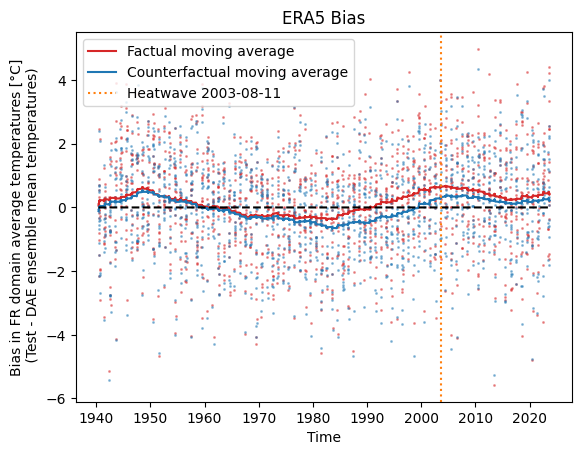

In [7]:
temporal_era5_bias_fact = x_eth_fact_reduced_mean.values - dpa_eth_fact_ensemble_mean_spat_mean.values
temporal_era5_bias_cf = x_eth_cf_reduced_mean - dpa_eth_cf_ensemble_mean_spat_mean.assign_coords(time=x_eth_cf_reduced_mean.time)
display(temporal_era5_bias_cf)

#time = temporal_era5_bias_fact.indexes["time"].to_datetimeindex()
time = x_eth_fact_reduced_mean.indexes["time"].to_datetimeindex()
plt.scatter(time, temporal_era5_bias_fact, color="tab:red", marker='.', alpha=0.4, s=5)
plt.scatter(time, temporal_era5_bias_cf.values, color="tab:blue", marker='.', alpha=0.4, s=5)
#temporal_era5_bias_fact.plot.scatter()

def moving_average_edge(x, window):
    kernel = np.ones(window)
    
    # Convolve data
    smoothed = np.convolve(x, kernel, mode='same')
    
    # Convolve ones to count how many valid points contribute at each position
    counts = np.convolve(np.ones_like(x), kernel, mode='same')
    
    return smoothed / counts

window = 200
smooth_era5_bias_fact = moving_average_edge(temporal_era5_bias_fact, window)
smooth_era5_bias_cf = moving_average_edge(temporal_era5_bias_cf.values, window)
plt.plot(time, smooth_era5_bias_fact, color="tab:red", label="Factual moving average")
plt.plot(time, smooth_era5_bias_cf, color="tab:blue", label="Counterfactual moving average")
plt.plot(time, np.zeros(1596), color='k', linestyle='--')

# 2003-08-11

plt.axvline(pd.Timestamp("2003-08-11"), color="tab:orange", linestyle=":", linewidth=1.5, label="Heatwave 2003-08-11")

#plt.ylim(-0.5,1.5)
plt.legend()
plt.xlabel("Time")
plt.ylabel("Bias in FR domain average temperatures [°C]\n (Test - DAE ensemble mean temperatures)")
plt.title("ERA5 Bias")
#plt.savefig(f"{standardization}_FR_time_resolved_bias_HW_marker.pdf")
plt.show()

## Draft

### DAE ensemble HW

Date: 2026-06-27T11:30:00.000000000
indices: <xarray.DataArray ()> Size: 8B
array(286)
Coordinates:
    time     object 8B 2026-06-27 00:00:00 <xarray.DataArray ()> Size: 8B
array(71)
Coordinates:
    time     object 8B 2026-06-27 00:00:00 <xarray.DataArray ()> Size: 8B
array(645)
Coordinates:
    time     object 8B 2026-06-27 00:00:00 <xarray.DataArray ()> Size: 8B
array(29)
Coordinates:
    time     object 8B 2026-06-27 00:00:00


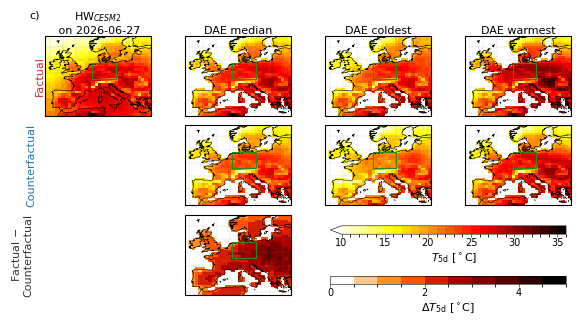

In [4]:
import matplotlib.pyplot as plt
import numpy as np
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.gridspec import GridSpec

# compute domain average temperature
weights = np.cos(np.deg2rad(dae_eth_fact.lat))
dae_eth_ens_spatial_mean = dae_eth_fact.weighted(weights).mean(dim=("lat","lon"))
weights = np.cos(np.deg2rad(dae_eth_cf.lat))
dae_eth_ens_spatial_mean_cf = dae_eth_cf.weighted(weights).mean(dim=("lat","lon"))

# ---------------------------------------------------------------------
# Publication figure settings
# ---------------------------------------------------------------------
FIG_WIDTH_MM = 153
FIG_WIDTH_IN = FIG_WIDTH_MM / 25.4
FIG_HEIGHT_IN = FIG_WIDTH_IN * 0.5

FONT_SIZE = 8

plt.rcParams.update({
    "font.size": FONT_SIZE,
    "axes.labelsize": FONT_SIZE,
    "axes.titlesize": FONT_SIZE,
    "xtick.labelsize": FONT_SIZE,
    "ytick.labelsize": FONT_SIZE,
    "legend.fontsize": FONT_SIZE - 1,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

# ---------------------------------------------------------------------
# Select event
# ---------------------------------------------------------------------
date = 5  # 2003-08-11
year = 2026
hw_month = "06"
hw_day = "27"

date_text = f"{year}-{hw_month}-{hw_day}"

print("Date:", ds_test_eth_fact.isel(time=date).time.values)

# ---------------------------------------------------------------------
# Compute ensemble means
# ---------------------------------------------------------------------
fact_dae_mean_h = fact_dae_mean
cf_dae_mean_h = cf_dae_mean

# ---------------------------------------------------------------------
# Find coldest / warmest members
# ---------------------------------------------------------------------
imin_fact = dae_eth_ens_spatial_mean.isel(time=date).argmin(dim="ensemble_member")
imax_fact = dae_eth_ens_spatial_mean.isel(time=date).argmax(dim="ensemble_member")
imin_cf = dae_eth_ens_spatial_mean_cf.isel(time=date).argmin(dim="ensemble_member")
imax_cf = dae_eth_ens_spatial_mean_cf.isel(time=date).argmax(dim="ensemble_member")
print("indices:", imin_fact, imax_fact, imin_cf, imax_cf)

# ---------------------------------------------------------------------
# Fields (no counterfactual CESM2 data available)
# ---------------------------------------------------------------------
fact_col0 = ds_test_eth_fact.isel(time=date)

fact_fields = [
    fact_col0,
    fact_dae_mean_h.isel(time=date),
    dae_eth_fact.isel(ensemble_member=imin_fact, time=date),
    dae_eth_fact.isel(ensemble_member=imax_fact, time=date),
]

cf_dae_fields = [
    cf_dae_mean_h.isel(time=date),
    dae_eth_cf.isel(ensemble_member=imin_cf, time=date),
    dae_eth_cf.isel(ensemble_member=imax_cf, time=date),
]

# Only difference panel: factual DAE median minus counterfactual DAE median
diff_median = fact_fields[1] - cf_dae_fields[0].values

fields = [*fact_fields,                # row 1: all absolute
          None, *cf_dae_fields,        # row 2: col 0 empty, cols 1-3 absolute
          None, diff_median, None, None]  # row 3: only col 1 (difference)

is_diff_col = [False, False, False, False,   # row 1
               False, False, False, False,   # row 2
               False, True,  False, False]   # row 3 - only panel (2,1)

titles = [
    f"HW$_{{CESM2}}$\n on {date_text}",
    "DAE median",
    "DAE coldest",
    "DAE warmest",
    "", "", "", "",
    "", "", "", "",
]

empty_indices = {4, 8}     # no data: panel off, but keep row labels
skip_indices = {10, 11}    # reserved for colorbars

# ---------------------------------------------------------------------
# Plot settings - absolute
# ---------------------------------------------------------------------
vmin = 10
vmax = 36
levels = np.linspace(vmin, vmax, 27)
cbar_ticks = np.arange(10, 37, 5)
cmap = "hot_r"

# Plot settings - difference (panel (2,1) only)
diff_vmin, diff_vmax = 0, 5
diff_levels = np.linspace(diff_vmin, diff_vmax, 11)
diff_cbar_ticks = np.arange(diff_vmin, diff_vmax + 1, 2)
diff_cmap = "gist_heat_r"

# France domain box
#box_lat_min, box_lat_max = 45, 50
#box_lon_min, box_lon_max = 0, 5
box_lons = [lon_min, lon_max, lon_max, lon_min, lon_min]
box_lats = [lat_min, lat_min, lat_max, lat_max, lat_min]

# ---------------------------------------------------------------------
# Create figure with GridSpec: 4 equal panel columns x 3 rows
# ---------------------------------------------------------------------
fig = plt.figure(figsize=(FIG_WIDTH_IN, FIG_HEIGHT_IN))

gs = GridSpec(
    3, 4,
    wspace=0.15,
    hspace=0.12,
    left=0.08,
    right=0.98,
    bottom=0.07,
    top=0.93,
    figure=fig,
)

axes = []
for row in range(3):
    for col in range(4):
        ax = fig.add_subplot(gs[row, col], projection=ccrs.PlateCarree())
        axes.append(ax)

# ---------------------------------------------------------------------
# Plot panels
# ---------------------------------------------------------------------
pc_main = None
pc_diff = None

for i, (ax, field, title, diff_col) in enumerate(zip(axes, fields, titles, is_diff_col)):

    if i in skip_indices:
        ax.set_visible(False)  # colorbars go here instead
        continue

    if i in empty_indices:
        ax.axis("off")         # hides map frame but keeps row-label text visible
        continue

    ax.add_feature(cfeature.LAND, facecolor="0.88", edgecolor="none", zorder=0)
    ax.coastlines(resolution="50m", linewidth=0.4, zorder=3)

    pc = field.plot(
        ax=ax,
        transform=ccrs.PlateCarree(),
        cmap=diff_cmap if diff_col else cmap,
        levels=diff_levels if diff_col else levels,
        vmin=diff_vmin if diff_col else vmin,
        vmax=diff_vmax if diff_col else vmax,
        add_colorbar=False,
        rasterized=True,
        zorder=2,
    )

    if diff_col:
        pc_diff = pc
    else:
        pc_main = pc

    ax.plot(box_lons, box_lats, transform=ccrs.PlateCarree(),
            color="forestgreen", linewidth=0.8, zorder=4)

    ax.gridlines(draw_labels=False, linewidth=0.25, color="0.5",
                 alpha=0.5, linestyle="--", zorder=1)

    ax.set_title(title, pad=1, fontsize=8)

# ---------------------------------------------------------------------
# Row labels
# ---------------------------------------------------------------------
axes[0].text(-0.05, 0.5, "Factual", transform=axes[0].transAxes,
             rotation=90, va="center", ha="center", color="tab:red")

axes[4].text(-0.05, 0.5, "Counterfactual", transform=axes[4].transAxes,
             rotation=90, va="center", ha="center", color="tab:blue")

axes[8].text(-0.125, 0.5, "Factual $-$\nCounterfactual", transform=axes[8].transAxes,
             rotation=90, va="center", ha="center", color="0.2")

# ---------------------------------------------------------------------
# Panel label
# ---------------------------------------------------------------------
axes[0].text(-0.15, 1.2, "c)", transform=axes[0].transAxes, va="bottom", ha="left")

# ---------------------------------------------------------------------
# Colorbars - stacked vertically in the empty bottom-right slots
# ---------------------------------------------------------------------
pos_left = gs[2, 2].get_position(fig)
pos_right = gs[2, 3].get_position(fig)

combined_x0 = pos_left.x0
combined_x1 = pos_right.x1
combined_y0 = pos_left.y0
combined_y1 = pos_left.y1

combined_w = combined_x1 - combined_x0
combined_h = combined_y1 - combined_y0


def stacked_hbar_rect(slot_index, n_slots=2, width_frac=0.9, height_frac=0.28, gap_frac=0.25):
    """Return [x0, y0, width, height] for one of n_slots stacked horizontal
    colorbars in the combined empty-panel region (slot 0 = top)."""
    w = combined_w * width_frac
    x0 = combined_x0 + (combined_w - w) / 2

    gap_h = combined_h * gap_frac
    usable_h = combined_h - gap_h * (n_slots - 1)
    band_h = usable_h / n_slots
    h = band_h * height_frac

    band_y1 = combined_y0 + combined_h - slot_index * (band_h + gap_h)
    band_y0 = band_y1 - band_h
    y0 = band_y0 + (band_h - h) / 2

    return [x0, y0, w, h]


# top bar: absolute temperature
cax_main = fig.add_axes(stacked_hbar_rect(slot_index=0))
cbar_main = fig.colorbar(
    pc_main, cax=cax_main, orientation="horizontal",
    boundaries=levels, ticks=cbar_ticks, spacing="proportional",
)
cbar_main.set_label(r"$T_{\mathrm{5d}}$ [$^\circ$C]", labelpad=2)
cbar_main.ax.tick_params(labelsize=FONT_SIZE - 1, width=0.4, length=2, pad=1)
cbar_main.outline.set_linewidth(0.4)

# bottom bar: difference (panel (2,1))
cax_diff = fig.add_axes(stacked_hbar_rect(slot_index=1))
cbar_diff = fig.colorbar(
    pc_diff, cax=cax_diff, orientation="horizontal",
    boundaries=diff_levels, ticks=diff_cbar_ticks, spacing="proportional",
)
cbar_diff.set_label(r"$\Delta T_{\mathrm{5d}}$ [$^\circ$C]", labelpad=2)
cbar_diff.ax.tick_params(labelsize=FONT_SIZE - 1, width=0.4, length=2, pad=1)
cbar_diff.outline.set_linewidth(0.4)

# ---------------------------------------------------------------------
# Save
# ---------------------------------------------------------------------
fig.savefig(f"{standardization}_Figure04c_updated.pdf", bbox_inches="tight")

plt.show()

Date: 2003-08-11 00:00:00
indices: <xarray.DataArray 'TREFHT' ()> Size: 8B
array(51)
Coordinates:
    time     object 8B 2003-08-11 11:30:00 <xarray.DataArray 'TREFHT' ()> Size: 8B
array(85)
Coordinates:
    time     object 8B 2003-08-11 11:30:00 <xarray.DataArray 'TREFHT' ()> Size: 8B
array(75)
Coordinates:
    time     object 8B 2003-08-11 11:30:00 <xarray.DataArray 'TREFHT' ()> Size: 8B
array(92)
Coordinates:
    time     object 8B 2003-08-11 11:30:00


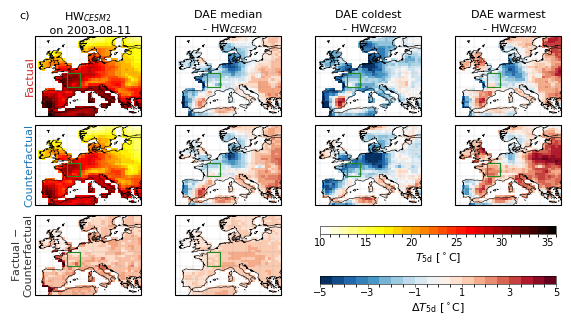

In [8]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.gridspec import GridSpec

# ---------------------------------------------------------------------
# Publication figure settings
# ---------------------------------------------------------------------
FIG_WIDTH_MM = 153
FIG_WIDTH_IN = FIG_WIDTH_MM / 25.4
FIG_HEIGHT_IN = FIG_WIDTH_IN * 0.5

FONT_SIZE = 8

plt.rcParams.update({
    "font.size": FONT_SIZE,
    "axes.labelsize": FONT_SIZE,
    "axes.titlesize": FONT_SIZE,
    "xtick.labelsize": FONT_SIZE,
    "ytick.labelsize": FONT_SIZE,
    "legend.fontsize": FONT_SIZE - 1,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

# ---------------------------------------------------------------------
# Select event
# ---------------------------------------------------------------------
date = 1211  # 2003-08-11
year = 2003
hw_month = "08"
hw_day = "11"

date_text = f"{year}-{hw_month}-{hw_day}"

print("Date:", ds_test_eth_fact.isel(time=date).time.values)

# ---------------------------------------------------------------------
# Compute ensemble means
# ---------------------------------------------------------------------
fact_dae_mean_h = fact_dae_mean.TREFHT
cf_dae_mean_h = cf_dae_mean.TREFHT

# ---------------------------------------------------------------------
# Find coldest / warmest members
# ---------------------------------------------------------------------
imin_fact = dae_eth_ens_spatial_mean.isel(time=date).argmin(dim="ensemble_member")
imax_fact = dae_eth_ens_spatial_mean.isel(time=date).argmax(dim="ensemble_member")
imin_cf = dae_eth_ens_spatial_mean_cf.isel(time=date).argmin(dim="ensemble_member")
imax_cf = dae_eth_ens_spatial_mean_cf.isel(time=date).argmax(dim="ensemble_member")
print("indices:", imin_fact, imax_fact, imin_cf, imax_cf)
# ---------------------------------------------------------------------
# Absolute fields — needed both for the diff-to-truth rows (1-2)
# and for the factual-minus-counterfactual row (3)
# ---------------------------------------------------------------------
fact_col0 = ds_test_eth_fact.TSA.isel(time=date)
cf_col0 = ds_test_eth_cf.TREFHT.isel(time=date)

fact_fields = [
    fact_col0,
    fact_dae_mean_h.isel(time=date),
    dae_eth_fact.TREFHT.isel(ensemble_member=imin_fact, time=date),
    dae_eth_fact.TREFHT.isel(ensemble_member=imax_fact, time=date),
]

cf_fields = [
    cf_col0,
    cf_dae_mean_h.isel(time=date),
    dae_eth_cf.TREFHT.isel(ensemble_member=imin_cf, time=date),
    dae_eth_cf.TREFHT.isel(ensemble_member=imax_cf, time=date),
]

# Row 1: factual — column 0 stays absolute, columns 1-3 become diffs to column 0
fact_diffs = [f - fact_col0.values for f in fact_fields[1:]]

# Row 2: counterfactual — same treatment
cf_diffs = [f - cf_col0.values for f in cf_fields[1:]]

# Row 3: factual minus counterfactual, panel-by-panel (uses the absolute fields)
diff_fields = [f - c.values for f, c in zip(fact_fields, cf_fields)]

fields = [fact_col0, *fact_diffs, cf_col0, *cf_diffs, *diff_fields]
is_diff_col = [False, True, True, True,   # row 1
               False, True, True, True,   # row 2
               True, True, True, True]    # row 3 — all diff-scale

titles = [
    #f"CESM2: HW$_{{{date_text}}}$",
    f"HW$_{{CESM2}}$\n on {date_text}",
    f"DAE median\n - HW$_{{CESM2}}$",
    f"DAE coldest\n - HW$_{{CESM2}}$",
    f"DAE warmest\n - HW$_{{CESM2}}$",
    "", "", "", "",
    "", "", "", "",
]

# indices (in the flat 12-panel layout) to leave empty: row 3, cols 2 and 3
skip_indices = {10, 11}

# ---------------------------------------------------------------------
# Plot settings — absolute (rows 1-2, column 0)
# ---------------------------------------------------------------------
vmin = 10
vmax = 36
levels = np.linspace(vmin, vmax, 27)
cbar_ticks = np.arange(10, 37, 5)
cmap = "hot_r"

# Plot settings — differences (rows 1-2 cols 1-3, and all of row 3)
diff_vmin, diff_vmax = -5, 5
diff_levels = np.linspace(diff_vmin, diff_vmax, 21)
diff_cbar_ticks = np.arange(diff_vmin, diff_vmax + 1, 2)
diff_cmap = "RdBu_r"

# France domain box
box_lat_min, box_lat_max = 45, 50
box_lon_min, box_lon_max = 0, 5
box_lons = [box_lon_min, box_lon_max, box_lon_max, box_lon_min, box_lon_min]
box_lats = [box_lat_min, box_lat_min, box_lat_max, box_lat_max, box_lat_min]

# ---------------------------------------------------------------------
# Create figure with GridSpec: 4 equal panel columns x 3 rows
# ---------------------------------------------------------------------
fig = plt.figure(figsize=(FIG_WIDTH_IN, FIG_HEIGHT_IN))

gs = GridSpec(
    3, 4,
    wspace=0.15,
    hspace=0.12,
    left=0.08,
    right=0.98,
    bottom=0.07,
    top=0.93,
    figure=fig,
)

axes = []
for row in range(3):
    for col in range(4):
        ax = fig.add_subplot(gs[row, col], projection=ccrs.PlateCarree())
        axes.append(ax)

# ---------------------------------------------------------------------
# Plot panels
# ---------------------------------------------------------------------
pc_main = None
pc_diff = None

for i, (ax, field, title, diff_col) in enumerate(zip(axes, fields, titles, is_diff_col)):

    if i in skip_indices:
        ax.set_visible(False)  # leave this panel empty (colorbars go here instead)
        continue

    ax.add_feature(cfeature.LAND, facecolor="0.88", edgecolor="none", zorder=0)
    ax.coastlines(resolution="50m", linewidth=0.4, zorder=3)

    pc = field.plot(
        ax=ax,
        transform=ccrs.PlateCarree(),
        cmap=diff_cmap if diff_col else cmap,
        levels=diff_levels if diff_col else levels,
        vmin=diff_vmin if diff_col else vmin,
        vmax=diff_vmax if diff_col else vmax,
        add_colorbar=False,
        rasterized=True,
        zorder=2,
    )

    if diff_col:
        pc_diff = pc
    else:
        pc_main = pc

    ax.plot(box_lons, box_lats, transform=ccrs.PlateCarree(),
            color="forestgreen", linewidth=0.8, zorder=4)

    ax.gridlines(draw_labels=False, linewidth=0.25, color="0.5",
                 alpha=0.5, linestyle="--", zorder=1)

    ax.set_title(title, pad=1, fontsize=8)

# ---------------------------------------------------------------------
# Row labels
# ---------------------------------------------------------------------
axes[0].text(-0.05, 0.5, "Factual", transform=axes[0].transAxes,
             rotation=90, va="center", ha="center", color="tab:red")

axes[4].text(-0.05, 0.5, "Counterfactual", transform=axes[4].transAxes,
             rotation=90, va="center", ha="center", color="tab:blue")

axes[8].text(-0.125, 0.5, "Factual $-$\nCounterfactual", transform=axes[8].transAxes,
             rotation=90, va="center", ha="center", color="0.2")

# ---------------------------------------------------------------------
# Panel label
# ---------------------------------------------------------------------
axes[0].text(-0.15, 1.2, "c)", transform=axes[0].transAxes, va="bottom", ha="left")

# ---------------------------------------------------------------------
# Colorbars — stacked vertically, spanning the combined width of both
# empty bottom-right panels (row 2, cols 2 AND 3 treated as one region)
# ---------------------------------------------------------------------

# bounding box of the *combined* two empty panel slots (cols 2-3, row 2)
pos_left = gs[2, 2].get_position(fig)
pos_right = gs[2, 3].get_position(fig)

combined_x0 = pos_left.x0
combined_x1 = pos_right.x1
combined_y0 = pos_left.y0
combined_y1 = pos_left.y1  # same row, same y-extent as pos_right

combined_w = combined_x1 - combined_x0
combined_h = combined_y1 - combined_y0

def stacked_hbar_rect(slot_index, n_slots=2, width_frac=0.9, height_frac=0.28, gap_frac=0.25):
    """Return [x0, y0, width, height] for a horizontal colorbar, one of
    `n_slots` stacked bars sharing the combined empty-panel region.
    slot_index=0 -> top bar, slot_index=1 -> bottom bar, etc.

    gap_frac controls the fraction of the combined height reserved as
    a gap between bars (independent of height_frac, which controls
    the bar's own thickness within its band).
    """
    w = combined_w * width_frac
    x0 = combined_x0 + (combined_w - w) / 2

    # reserve a gap in the middle, split remaining height into n_slots bands
    gap_h = combined_h * gap_frac
    usable_h = combined_h - gap_h * (n_slots - 1)
    band_h = usable_h / n_slots
    h = band_h * height_frac

    # stack top-to-bottom, inserting gap_h between consecutive bands
    band_y1 = combined_y0 + combined_h - slot_index * (band_h + gap_h)
    band_y0 = band_y1 - band_h
    y0 = band_y0 + (band_h - h) / 2

    return [x0, y0, w, h]

# top bar: main (absolute temperature) colorbar
cax_main = fig.add_axes(stacked_hbar_rect(slot_index=0))
cbar_main = fig.colorbar(
    pc_main, cax=cax_main, orientation="horizontal",
    boundaries=levels, ticks=cbar_ticks, spacing="proportional",
)
cbar_main.set_label(r"$T_{\mathrm{5d}}$ [$^\circ$C]", labelpad=2)
cbar_main.ax.tick_params(labelsize=FONT_SIZE - 1, width=0.4, length=2, pad=1)
cbar_main.outline.set_linewidth(0.4)

# bottom bar: difference colorbar
cax_diff = fig.add_axes(stacked_hbar_rect(slot_index=1))
cbar_diff = fig.colorbar(
    pc_diff, cax=cax_diff, orientation="horizontal",
    boundaries=diff_levels, ticks=diff_cbar_ticks, spacing="proportional",
)
cbar_diff.set_label(r"$\Delta T_{\mathrm{5d}}$ [$^\circ$C]", labelpad=2)
cbar_diff.ax.tick_params(labelsize=FONT_SIZE - 1, width=0.4, length=2, pad=1)
cbar_diff.outline.set_linewidth(0.4)

#fig.subplots_adjust(left=0.0, right=1.0, top=1.0, bottom=0.05, wspace=0.0, hspace=0.1)

# ---------------------------------------------------------------------
# Save
# ---------------------------------------------------------------------
fig.savefig(f"{standardization}_Figure04c_updated.pdf", bbox_inches="tight")

plt.show()

### Summer time series

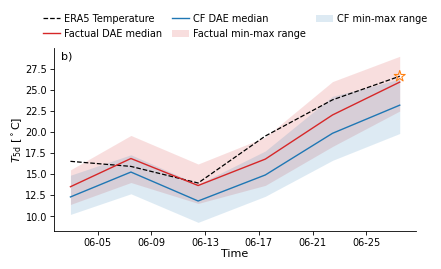

In [5]:
# using median of ensemble of regional mean values
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.patches as mpatches
from matplotlib.legend_handler import HandlerTuple

# ---------------------------------------------------------------------
# Publication-ready settings
# ---------------------------------------------------------------------
FIG_WIDTH_MM = 100#153
FIG_WIDTH_IN = FIG_WIDTH_MM / 25.4
FIG_HEIGHT_IN = FIG_WIDTH_IN * 0.8

FONT_SIZE = 8
SMALL_FONT_SIZE = 7

plt.rcParams.update({
    "font.size": FONT_SIZE,
    "axes.labelsize": FONT_SIZE,
    "axes.titlesize": FONT_SIZE,
    "xtick.labelsize": SMALL_FONT_SIZE,
    "ytick.labelsize": SMALL_FONT_SIZE,
    "legend.fontsize": SMALL_FONT_SIZE,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "axes.linewidth": 0.6,
    "xtick.major.width": 0.6,
    "ytick.major.width": 0.6,
    "xtick.minor.width": 0.5,
    "ytick.minor.width": 0.5,
    "xtick.major.size": 3,
    "ytick.major.size": 3,
    "xtick.minor.size": 1.8,
    "ytick.minor.size": 1.8,
})

# ---------------------------------------------------------------------
# Helpers
# ---------------------------------------------------------------------
def weighted_domain_mean(da, lat_min, lat_max, lon_min, lon_max):
    """Latitude-weighted spatial mean over a rectangular domain."""
    da_domain = da.sel(
        lat=slice(lat_min, lat_max),
        lon=slice(lon_min, lon_max),
    )

    weights = np.cos(np.deg2rad(da_domain["lat"]))
    weights = xr.DataArray(
        weights,
        coords={"lat": da_domain["lat"]},
        dims=["lat"],
    )

    return da_domain.weighted(weights).mean(dim=("lat", "lon"))


def prepare_dpa_time_series(
    dpa_ens_cf,
    dpa_ens_mean_cf,
    true_fact,
    dpa_ens_fact,
    dpa_ens_mean_fact,
    lat_min,
    lat_max,
    lon_min,
    lon_max,
    n_stds=2,
    true_cf=None,
):
    if isinstance(dpa_ens_cf, xr.Dataset):
        dpa_ens_cf = dpa_ens_cf.TREFHT

    if isinstance(dpa_ens_fact, xr.Dataset):
        dpa_ens_fact = dpa_ens_fact.TREFHT

    true_cf_mean = (
        weighted_domain_mean(true_cf, lat_min, lat_max, lon_min, lon_max)
        if true_cf is not None else None
    )

    true_fact_mean = weighted_domain_mean(
        true_fact, lat_min, lat_max, lon_min, lon_max
    )

    dpa_cf_mean_pre = weighted_domain_mean(
        dpa_ens_cf, lat_min, lat_max, lon_min, lon_max
    )

    dpa_fact_mean_pre = weighted_domain_mean(
        dpa_ens_fact, lat_min, lat_max, lon_min, lon_max
    )

    # medians of DAE regional-mean ensemble
    dpa_cf_mean = dpa_cf_mean_pre.median(dim="ensemble_member")
    dpa_fact_mean = dpa_fact_mean_pre.median(dim="ensemble_member")

    # envelopes: min/max
    fact_lower = dpa_fact_mean_pre.min(dim="ensemble_member")
    fact_upper = dpa_fact_mean_pre.max(dim="ensemble_member")

    cf_lower = dpa_cf_mean_pre.min(dim="ensemble_member")
    cf_upper = dpa_cf_mean_pre.max(dim="ensemble_member")

    return {
        "true_cf": true_cf_mean,
        "true_fact": true_fact_mean,
        "dpa_cf_mean": dpa_cf_mean,
        "dpa_fact_mean": dpa_fact_mean,
        "cf_lower": cf_lower,
        "cf_upper": cf_upper,
        "fact_lower": fact_lower,
        "fact_upper": fact_upper,
        "n_stds": n_stds,
    }


def _to_datetime_index(da):
    """Return a pandas DatetimeIndex for both cftime and numpy time axes."""
    idx = da.indexes["time"]
    if hasattr(idx, "to_datetimeindex"):   # CFTimeIndex
        return idx.to_datetimeindex()
    return idx                              # already a DatetimeIndex


def _select_year(da, plot_year):
    if plot_year is None:
        return da

    try:
        return da.sel(time=str(plot_year))
    except Exception:
        time = _to_datetime_index(da)
        return da.isel(time=time.year == int(plot_year))


def plot_dpa_time_series_on_ax(
    ax,
    ts,
    plot_year=None,
    event_date=None,
    panel_label="b)",
    ylabel=r"$\mathrm{T}_{5d}$ [$^\circ$C]",
):
    true_cf = (_select_year(ts["true_cf"], plot_year)
               if ts["true_cf"] is not None else None)
    true_fact = _select_year(ts["true_fact"], plot_year)
    dpa_cf_mean = _select_year(ts["dpa_cf_mean"], plot_year)
    dpa_fact_mean = _select_year(ts["dpa_fact_mean"], plot_year)
    cf_lower = _select_year(ts["cf_lower"], plot_year)
    cf_upper = _select_year(ts["cf_upper"], plot_year)
    fact_lower = _select_year(ts["fact_lower"], plot_year)
    fact_upper = _select_year(ts["fact_upper"], plot_year)

    time = _to_datetime_index(true_fact)

    ax.plot(
        time,
        true_fact.values,
        color="black",
        linewidth=0.9,
        linestyle="--",
        label=f"ERA5 Temperature",
    )

    if true_cf is not None:
        ax.plot(
            time,
            true_cf.values,
            color="tab:cyan",
            linewidth=0.8,
            linestyle="-",
            label=r"$\mathrm{\mathrm{CESM2\text{-}ERA5_{cf\text{-}nudge}}}$",
        )

    ax.plot(
        time,
        dpa_fact_mean.values,
        color="tab:red",
        linewidth=1.0,
        label="Factual DAE median",
    )

    ax.plot(
        time,
        dpa_cf_mean.values,
        color="tab:blue",
        linewidth=1.0,
        label="CF DAE median",
    )

    ax.fill_between(
        time,
        fact_lower.values,
        fact_upper.values,
        color="tab:red",
        alpha=0.15,
        linewidth=0,
        label="Factual min-max range",
    )

    ax.fill_between(
        time,
        cf_lower.values,
        cf_upper.values,
        color="tab:blue",
        alpha=0.15,
        linewidth=0,
        label="CF min-max range",
    )

    # event marker
    if event_date is not None:
        event_sel = true_fact.sel(time=event_date)
        ax.scatter(
            _to_datetime_index(event_sel),
            event_sel.values,
            marker="*",
            s=70,
            facecolors="none",
            edgecolors="tab:orange",
            linewidth=0.75,
            zorder=5,
        )

    ax.set_ylabel(ylabel, labelpad=1)
    ax.set_xlabel("Time", labelpad=1)

    # ---------------------------------------------------------------------
    # Date formatting
    # ---------------------------------------------------------------------
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%m-%d"))

    ax.tick_params(
        axis="both",
        which="major",
        direction="out",
        pad=2,
    )

    ax.text(
        0.02,
        0.98,
        panel_label,
        transform=ax.transAxes,
        fontsize=FONT_SIZE,
        ha="left",
        va="top",
    )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.legend(
        loc="lower center",
        bbox_to_anchor=(0.5, 1.02),
        ncol=3,
        frameon=False,
        handlelength=1.8,
        columnspacing=1.0,
        handletextpad=0.4,
        borderaxespad=0.2,
    )


# ---------------------------------------------------------------------
# DAE time series data
# ---------------------------------------------------------------------
year_tp = year

ts = prepare_dpa_time_series(
    # true_cf=ds_test_eth_cf.isel(time=slice(0, 4769)),  # not available
    dpa_ens_cf=dae_eth_cf.isel(time=slice(0, 4769)),
    dpa_ens_mean_cf=cf_dae_mean.isel(time=slice(0, 4769)),

    true_fact=ds_test_eth_fact.isel(time=slice(0, 4769)),
    dpa_ens_fact=dae_eth_fact.isel(time=slice(0, 4769)),
    dpa_ens_mean_fact=fact_dae_mean.isel(time=slice(0, 4769)),

    lat_min=lat_min,
    lat_max=lat_max,
    lon_min=lon_min,
    lon_max=lon_max,
    n_stds=2,
)

# ---------------------------------------------------------------------
# Figure: single full-width panel
# ---------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(FIG_WIDTH_IN, FIG_HEIGHT_IN))

plot_dpa_time_series_on_ax(
    ax,
    ts,
    plot_year=year_tp,
    event_date=date_text,
    panel_label="b)",
    ylabel=r"$T_{\mathrm{5d}}$ [$^\circ$C]",
)

# ---------------------------------------------------------------------
# Final layout
# ---------------------------------------------------------------------
fig.subplots_adjust(
    left=0.065,
    right=0.985,
    bottom=0.20,
    top=0.78,      # room for the two-row legend above the axes
)

# ---------------------------------------------------------------------
# Save
# ---------------------------------------------------------------------
fig.savefig(
    f"{standardization}_FR_median_time_series_{year_tp}.pdf",
    bbox_inches="tight",
    pad_inches=0.01,
)

plt.show()

In [19]:
# using median of ensemble of regional mean values
import matplotlib.dates as mdates
import matplotlib.patches as mpatches
from matplotlib.legend_handler import HandlerTuple

# ---------------------------------------------------------------------
# Publication-ready settings
# ---------------------------------------------------------------------
FIG_WIDTH_MM = 153
FIG_WIDTH_IN = FIG_WIDTH_MM / 25.4
FIG_HEIGHT_IN = FIG_WIDTH_IN * 0.3

FONT_SIZE = 8
SMALL_FONT_SIZE = 7

plt.rcParams.update({
    "font.size": FONT_SIZE,
    "axes.labelsize": FONT_SIZE,
    "axes.titlesize": FONT_SIZE,
    "xtick.labelsize": SMALL_FONT_SIZE,
    "ytick.labelsize": SMALL_FONT_SIZE,
    "legend.fontsize": SMALL_FONT_SIZE,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "axes.linewidth": 0.6,
    "xtick.major.width": 0.6,
    "ytick.major.width": 0.6,
    "xtick.minor.width": 0.5,
    "ytick.minor.width": 0.5,
    "xtick.major.size": 3,
    "ytick.major.size": 3,
    "xtick.minor.size": 1.8,
    "ytick.minor.size": 1.8,
})

# ---------------------------------------------------------------------
# Helpers
# ---------------------------------------------------------------------
def weighted_domain_mean(da, lat_min, lat_max, lon_min, lon_max):
    """Latitude-weighted spatial mean over a rectangular domain."""
    da_domain = da.sel(
        lat=slice(lat_min, lat_max),
        lon=slice(lon_min, lon_max),
    )

    weights = np.cos(np.deg2rad(da_domain["lat"]))
    weights = xr.DataArray(
        weights,
        coords={"lat": da_domain["lat"]},
        dims=["lat"],
    )

    return da_domain.weighted(weights).mean(dim=("lat", "lon"))


def prepare_dpa_time_series(
    true_cf,
    dpa_ens_cf,
    dpa_ens_mean_cf,
    true_fact,
    dpa_ens_fact,
    dpa_ens_mean_fact,
    lat_min,
    lat_max,
    lon_min,
    lon_max,
    n_stds=2,
):
    if isinstance(dpa_ens_cf, xr.Dataset):
        dpa_ens_cf = dpa_ens_cf.TREFHT

    if isinstance(dpa_ens_fact, xr.Dataset):
        dpa_ens_fact = dpa_ens_fact.TREFHT

    true_cf_mean = weighted_domain_mean(
        true_cf, lat_min, lat_max, lon_min, lon_max
    )

    true_fact_mean = weighted_domain_mean(
        true_fact, lat_min, lat_max, lon_min, lon_max
    )

    dpa_cf_mean_pre = weighted_domain_mean(
        dpa_ens_cf, lat_min, lat_max, lon_min, lon_max
        #dpa_ens_mean_cf, lat_min, lat_max, lon_min, lon_max
    )

    dpa_fact_mean_pre = weighted_domain_mean(
        dpa_ens_fact, lat_min, lat_max, lon_min, lon_max
        #dpa_ens_mean_fact, lat_min, lat_max, lon_min, lon_max
    )

    # compute medians of DAE regional means ensemble 
    dpa_cf_mean = dpa_cf_mean_pre.median(dim="ensemble_member")
    dpa_fact_mean = dpa_fact_mean_pre.median(dim="ensemble_member")

    # envelopes
    # quantiles
    #fact_lower = dpa_fact_mean_pre.quantile(0.025, dim="ensemble_member")
    #fact_upper = dpa_fact_mean_pre.quantile(0.975, dim="ensemble_member")

    #cf_lower = dpa_cf_mean_pre.quantile(0.025, dim="ensemble_member")
    #cf_upper = dpa_cf_mean_pre.quantile(0.975, dim="ensemble_member")

    # min/max
    fact_lower = dpa_fact_mean_pre.min(dim="ensemble_member")
    fact_upper = dpa_fact_mean_pre.max(dim="ensemble_member")
    
    cf_lower = dpa_cf_mean_pre.min(dim="ensemble_member")
    cf_upper = dpa_cf_mean_pre.max(dim="ensemble_member")

    return {
        "true_cf": true_cf_mean,
        "true_fact": true_fact_mean,
        "dpa_cf_mean": dpa_cf_mean,
        "dpa_fact_mean": dpa_fact_mean,
        #"cf_lower": dpa_cf_mean - n_stds * dpa_cf_std,
        #"cf_upper": dpa_cf_mean + n_stds * dpa_cf_std,
        "cf_lower": cf_lower,
        "cf_upper": cf_upper,
        "fact_lower": fact_lower,
        "fact_upper": fact_upper,
        "n_stds": n_stds,
    }


def _to_datetime_index(da):
    return da.indexes["time"].to_datetimeindex()


def _select_year(da, plot_year):
    if plot_year is None:
        return da

    try:
        return da.sel(time=str(plot_year))
    except Exception:
        time = _to_datetime_index(da)
        return da.isel(time=time.year == int(plot_year))


def plot_dpa_time_series_on_ax(
    ax,
    ts,
    plot_year=None,
    panel_label="b)",
    ylabel=r"$\mathrm{T}_{5d}$ [$^\circ$C]",
):
    true_cf = _select_year(ts["true_cf"], plot_year)
    true_fact = _select_year(ts["true_fact"], plot_year)
    dpa_cf_mean = _select_year(ts["dpa_cf_mean"], plot_year)
    dpa_fact_mean = _select_year(ts["dpa_fact_mean"], plot_year)
    cf_lower = _select_year(ts["cf_lower"], plot_year)
    cf_upper = _select_year(ts["cf_upper"], plot_year)
    fact_lower = _select_year(ts["fact_lower"], plot_year)
    fact_upper = _select_year(ts["fact_upper"], plot_year)

    time = _to_datetime_index(true_fact)



    

    ax.plot(
        time,
        true_fact.values,
        color="black",
        linewidth=0.9,
        linestyle="--",
        label=r"$\mathrm{\mathrm{CESM2\text{-}ERA5_{fact\text{-}nudge}}}$",
    )

    ax.plot(
        time,
        true_cf.values,
        color="tab:cyan",
        linewidth=0.8,
        linestyle="-",
        label=r"$\mathrm{\mathrm{CESM2\text{-}ERA5_{cf\text{-}nudge}}}$",
    )
    
    ax.plot(
        time,
        dpa_fact_mean.values,
        color="tab:red",
        linewidth=1.0,
        label="Factual DAE median",
    )
    
    ax.plot(
        time,
        dpa_cf_mean.values,
        color="tab:blue",
        linewidth=1.0,
        label="CF DAE median",
    )

    

    ax.fill_between(
        time,
        fact_lower.values,
        fact_upper.values,
        color="tab:red",
        alpha=0.15,
        linewidth=0,
        label="Factual min-max range"
        #label=rf"Factual DAE $\pm {ts['n_stds']}\sigma$",
    )
    
    ax.fill_between(
        time,
        cf_lower.values,
        cf_upper.values,
        color="tab:blue",
        alpha=0.15,
        linewidth=0,
        label="CF min-max range"
        #label=rf"CF DAE $\pm {ts['n_stds']}\sigma$",
    )

    


    

    time_2003 = true_fact.sel(time="2003-08-11").indexes["time"].to_datetimeindex()
    heatwave_value = true_fact.sel(time="2003-08-11").values

    ax.scatter(
    time_2003,
    heatwave_value,
    marker="*",
    s=70,
    facecolors="none",
    edgecolors="tab:orange",
    linewidth=0.75,
    zorder=5,
    )
    
    ax.set_ylabel(ylabel, labelpad=1)
    ax.set_xlabel("Time", labelpad=1)

    #ax.xaxis.set_major_locator(mdates.MonthLocator(interval=1))
    #ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))

    # ---------------------------------------------------------------------
    # Date formatting
    # ---------------------------------------------------------------------
    #ax.xaxis.set_major_locator(mdates.WeekdayLocator(interval=1))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%m-%d"))
    
    #ax.xaxis.set_minor_locator(mdates.DayLocator(interval=3))

    ax.tick_params(
        axis="both",
        which="major",
        direction="out",
        pad=2,
    )
    ax.tick_params(
    axis="x",
    which="major",
    #rotation=45,
    )

    ax.text(
        0.02,
        0.98,
        panel_label,
        transform=ax.transAxes,
        fontsize=FONT_SIZE,
        #fontweight="bold",
        ha="left",
        va="top",
    )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    
    # ADD PATCH
    # two-color legend entry
    patch1 = mpatches.Patch(facecolor='tab:red', alpha=0.2, edgecolor='none')
    patch2 = mpatches.Patch(facecolor='tab:blue', alpha=0.2, edgecolor='none')
    
    # existing legend items
    handles, labels = ax.get_legend_handles_labels()
    
    # append tuple of patches
    handles.append((patch1, patch2))
    labels.append("Fact / CF DAE \n min-max range")
    ax.legend(
        #handles=handles,
        #labels=labels,
        #handler_map={tuple: HandlerTuple(ndivide=None)},
        loc="lower center",
        bbox_to_anchor=(0.5, 1.02),
        ncol=3,
        frameon=False,
        handlelength=1.8,
        columnspacing=1.0,
        handletextpad=0.4,
        borderaxespad=0.2,
    )


# ---------------------------------------------------------------------
# FR domain
# --------------------------------------------------------------------fr

# ---------------------------------------------------------------------
# Left-panel data: absolute time series
# ---------------------------------------------------------------------
ds_1300 = ds_test_eth_fact

trefht_1300_abs = ut.get_ger_1d_data(
    ds_1300,
    lat_min=lat_min,
    lat_max=lat_max,
    lon_min=lon_min,
    lon_max=lon_max,
)

ds_5day_jja_celsius = trefht_1300_abs

time = ds_5day_jja_celsius.indexes["time"].to_datetimeindex()
time_2003 = ds_5day_jja_celsius.sel(time="2003-08-11").indexes["time"].to_datetimeindex()
heatwave_value = ds_5day_jja_celsius.sel(time=date_text).values



# ---------------------------------------------------------------------
# Right-panel data: DAE time series
# ---------------------------------------------------------------------
year_tp = year

ts = prepare_dpa_time_series(
    true_cf=ds_test_eth_cf.isel(time=slice(0, 4769)),
    dpa_ens_cf=dae_eth_cf.isel(time=slice(0, 4769)),
    dpa_ens_mean_cf=cf_dae_mean.isel(time=slice(0, 4769)),

    true_fact=ds_test_eth_fact.isel(time=slice(0, 4769)),
    dpa_ens_fact=dae_eth_fact.isel(time=slice(0, 4769)),
    dpa_ens_mean_fact=fact_dae_mean.isel(time=slice(0, 4769)),

    lat_min=lat_min,
    lat_max=lat_max,
    lon_min=lon_min,
    lon_max=lon_max,
    n_stds=2,
)

# ---------------------------------------------------------------------
# Combined figure: 153 mm total width, 1/1 width ratio
# ---------------------------------------------------------------------
fig = plt.figure(figsize=(FIG_WIDTH_IN, FIG_HEIGHT_IN))

gs = fig.add_gridspec(
    nrows=1,
    ncols=2,
    width_ratios=[0.4, 0.6],
    wspace=0.35,
)

ax_left = fig.add_subplot(gs[0, 0])
ax_right = fig.add_subplot(gs[0, 1])

# =====================================================================
# LEFT PANEL: long-term absolute time series
# =====================================================================
ax_left.scatter(
    time,
    ds_5day_jja_celsius.values,
    marker=".",
    s=4,
    color="black",
    alpha=0.75,
    linewidths=0,
    label=r"JJA $T_{\mathrm{5d}}$",
)

ax_left.scatter(
    time_2003,
    heatwave_value,
    marker="*",
    s=70,
    facecolors="none",
    edgecolors="tab:orange",
    linewidth=0.75,
    zorder=5,
)

ax_left.annotate(
    "2003 heatwave",
    xy=(time_2003[0], heatwave_value),
    xytext=(4, 3),
    textcoords="offset points",
    fontsize=SMALL_FONT_SIZE,
    color="tab:orange",
    ha="left",
    va="bottom",
)

ax_left.set_ylabel(r"$T_{\mathrm{5d}}$ [$^\circ$C]", labelpad=1)
ax_left.set_xlabel("Year", labelpad=1)

ax_left.xaxis.set_major_locator(mdates.YearLocator(base=20))
ax_left.xaxis.set_minor_locator(mdates.YearLocator(base=10))
ax_left.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

ax_left.tick_params(
    axis="both",
    which="major",
    direction="out",
    pad=2,
)

ax_left.tick_params(
    axis="x",
    which="minor",
    direction="out",
)

ax_left.spines["top"].set_visible(False)
ax_left.spines["right"].set_visible(False)

ax_left.legend(
    loc="upper left",
    bbox_to_anchor=(0.15, 0.98),
    frameon=True,
    handletextpad=0.4,
    borderaxespad=0.0,
    labelspacing=0.35,
    fontsize=SMALL_FONT_SIZE,
)

ax_left.text(
    0.02,
    0.98,
    "a)",
    transform=ax_left.transAxes,
    fontsize=FONT_SIZE,
    #fontweight="bold",
    ha="left",
    va="top",
)

# =====================================================================
# RIGHT PANEL: DAE event time series
# =====================================================================
plot_dpa_time_series_on_ax(
    ax_right,
    ts,
    plot_year=year_tp,
    panel_label="b)",
    ylabel=r"$T_{\mathrm{5d}}$ [$^\circ$C]",
)

# ---------------------------------------------------------------------
# Final layout
# ---------------------------------------------------------------------
fig.subplots_adjust(
    left=0.065,
    right=0.985,
    bottom=0.20,
    top=0.96,
)

# ---------------------------------------------------------------------
# Save
# ---------------------------------------------------------------------
#fig.savefig(
#    f"{standardization}_FR_median_combined_time_series_{year_tp}.pdf",
#    bbox_inches="tight",
#    pad_inches=0.01,
#)

plt.show()



AttributeError: 'DatetimeIndex' object has no attribute 'to_datetimeindex'

### Add risk-based distributions

In [10]:
# Factual ERA5 test data
ds_test_le_fact_unstacked = ds_test_eth_fact

# ds dims: time=1596, lat=32, lon=32
n_ens = 1
n_t = 1596

if ds_test_le_fact_unstacked.sizes["time"] != n_ens * n_t:
    raise ValueError("time dimension does not match 100 * 4769")


# factual distribution (1988-2018)
trefht_le_fact_1988_2018 = ds_test_le_fact_unstacked.TSA.sel(time=slice("1988", "2018"))

trefht_le_fact_0811 = trefht_le_fact_1988_2018.sel(
    time=(trefht_le_fact_1988_2018.time.dt.month == 8) & (trefht_le_fact_1988_2018.time.dt.day == 11)
)
trefht_le_fact_0811

# counterfactual distribution (1940-1970)
trefht_le_fact_1940_1970 = ds_test_le_fact_unstacked.TSA.sel(time=slice("1940", "1970"))

trefht_le_cf_0811 = trefht_le_fact_1940_1970.sel(
    time=(trefht_le_fact_1940_1970.time.dt.month == 8) & (trefht_le_fact_1940_1970.time.dt.day == 11)
)
display(trefht_le_fact_0811)

# compute domain averages
trefht_le_fact_0811_ger = ut.get_ger_1d_data(trefht_le_fact_0811, 
                                     lat_min = fr_lat_min,
                                     lat_max = fr_lat_max,
                                     lon_min = fr_lon_min,
                                     lon_max = fr_lon_max
                                            )
trefht_le_cf_0811_ger = ut.get_ger_1d_data(trefht_le_cf_0811,
                                     lat_min = fr_lat_min,
                                     lat_max = fr_lat_max,
                                     lon_min = fr_lon_min,
                                     lon_max = fr_lon_max
                                          )

display(trefht_le_fact_0811_ger)
display(trefht_le_cf_0811_ger)

<xarray.DataArray 'TSA' (time: 31, lat: 32, lon: 32)> Size: 127kB
array([[[      nan,       nan,       nan, ...,       nan,       nan,
               nan],
        [      nan,       nan,       nan, ..., 28.816772,       nan,
               nan],
        [      nan,       nan,       nan, ...,       nan,       nan,
               nan],
        ...,
        [      nan,       nan,       nan, ..., 14.13855 , 14.62088 ,
         15.058868],
        [      nan,       nan,       nan, ..., 12.856964, 13.685425,
         14.358398],
        [      nan,       nan,       nan, ..., 12.057922, 12.546875,
         13.190369]],

       [[      nan,       nan,       nan, ...,       nan,       nan,
               nan],
        [      nan,       nan,       nan, ..., 29.26294 ,       nan,
               nan],
        [      nan,       nan,       nan, ...,       nan,       nan,
               nan],
...
        [      nan,       nan,       nan, ..., 19.18457 , 19.457123,
         19.588928],
        [      nan,       nan,       nan, ..., 17.65326 , 18.205994,
         18.460266],
        [      nan,       nan,       nan, ..., 16.861328, 17.148499,
         17.387115]],

       [[      nan,       nan,       nan, ...,       nan,       nan,
               nan],
        [      nan,       nan,       nan, ..., 29.693817,       nan,
               nan],
        [      nan,       nan,       nan, ...,       nan,       nan,
               nan],
        ...,
        [      nan,       nan,       nan, ..., 20.32608 , 21.019684,
         21.630035],
        [      nan,       nan,       nan, ..., 19.458435, 20.240845,
         20.77185 ],
        [      nan,       nan,       nan, ..., 18.886658, 19.039581,
         19.38086 ]]], shape=(31, 32, 32), dtype=float32)
Coordinates:
  * time     (time) object 248B 1988-08-11 00:00:00 ... 2018-08-11 00:00:00
  * lat      (lat) float64 256B 34.4 35.34 36.28 37.23 ... 61.73 62.67 63.61
  * lon      (lon) float64 256B -11.25 -10.0 -8.75 -7.5 ... 25.0 26.25 27.5

<xarray.DataArray 'TSA' (time: 31)> Size: 248B
array([21.59380749, 20.02027081, 21.82443774, 20.39833137, 20.7248508 ,
       18.41356076, 21.13030235, 22.30544065, 19.46429882, 25.17236439,
       26.28101116, 19.99866433, 22.30491072, 18.19825447, 17.29620334,
       30.04260321, 23.26954793, 19.15791375, 17.06320591, 18.36845752,
       19.30485512, 20.44605439, 19.95551542, 18.10880401, 21.50974186,
       19.26291127, 19.51690601, 23.1456915 , 18.19198154, 17.29680258,
       20.72759574])
Coordinates:
  * time     (time) object 248B 1988-08-11 00:00:00 ... 2018-08-11 00:00:00

<xarray.DataArray 'TSA' (time: 31)> Size: 248B
array([19.56110133, 17.35394231, 18.6035395 , 17.72391923, 22.96856052,
       17.99579192, 19.52143837, 22.0039014 , 17.48939157, 19.39497609,
       20.84548245, 16.87563192, 20.99236573, 23.26258241, 16.75424471,
       16.69341875, 19.82386667, 19.4537859 , 19.8284878 , 20.41957905,
       17.40465012, 19.26975829, 18.25656993, 17.12334831, 16.37479074,
       19.32024123, 20.90357055, 18.61257228, 18.47126906, 22.80588635,
       17.66773918])
Coordinates:
  * time     (time) object 248B 1940-08-11 00:00:00 ... 1970-08-11 00:00:00

### Bootstrap ensemble statistics

In [6]:
# define functions
from matplotlib.patches import Patch

# ---------------------------------------------------------------------
# Region settings
# ---------------------------------------------------------------------
LAT_MIN, LAT_MAX = lat_min, lat_max
LON_MIN, LON_MAX = lon_min, lon_max
print(LAT_MIN, LAT_MAX, LON_MIN, LON_MAX)

TIME_SLICE = slice(0, 4769)
YEAR = year
DATE = date_text

N_BOOT = 2000
ALPHA = 0.05
TEXT_FS = 8

# ---------------------------------------------------------------------
# Helper functions
# ---------------------------------------------------------------------
def area_weighted_mean(data, lat_min, lat_max, lon_min, lon_max, time=None):
    """Compute cosine-latitude weighted regional mean."""
    regional = data.sel(lat=slice(lat_min, lat_max), lon=slice(lon_min, lon_max))
    if time is not None:
        regional = regional.sel(time=time)

    weights = np.cos(np.deg2rad(regional["lat"]))
    weights_da = xr.DataArray(weights, coords={"lat": regional["lat"]}, dims=["lat"])

    return regional.weighted(weights_da).mean(dim=("lat", "lon"))

def bootstrap_median(values, n_boot=1000, alpha=0.05, rng=None):
    """
    Bootstrap the sample median and return:
    - median of bootstrap medians
    - lower / upper CI of bootstrap medians
    - all bootstrap medians
    """
    values = np.asarray(values).ravel()
    n = values.size

    if rng is None:
        rng = np.random.default_rng()

    boot_medians = np.empty(n_boot, dtype=float)

    for i in range(n_boot):
        sample = rng.choice(values, size=n, replace=True)
        boot_medians[i] = np.median(sample)

    lower_q = 100 * (alpha / 2)
    upper_q = 100 * (1 - alpha / 2)

    median_of_medians = np.median(boot_medians)
    ci_low = np.percentile(boot_medians, lower_q)
    ci_high = np.percentile(boot_medians, upper_q)

    return median_of_medians, ci_low, ci_high, boot_medians

def bootstrap_kde_ci(samples, x_grid, n_boot=1000, alpha=0.05, rng=None, bw_method=None):
    """
    Bootstrap pointwise confidence intervals for a Gaussian KDE.

    Returns
    -------
    kde_ref : ndarray
        KDE estimated from the original sample.
    kde_low : ndarray
        Lower pointwise confidence bound.
    kde_high : ndarray
        Upper pointwise confidence bound.
    kde_boot : ndarray
        All bootstrap KDE evaluations.
    """
    samples = np.asarray(samples).ravel()
    n = samples.size

    if rng is None:
        rng = np.random.default_rng()

    kde_boot = np.empty((n_boot, len(x_grid)), dtype=float)

    for i in range(n_boot):
        resample = rng.choice(samples, size=n, replace=True)
        kde = gaussian_kde(resample, bw_method=bw_method)
        kde_boot[i] = kde(x_grid)

    kde_ref = gaussian_kde(samples, bw_method=bw_method)(x_grid)

    lower_q = 100 * (alpha / 2)
    upper_q = 100 * (1 - alpha / 2)

    kde_low = np.percentile(kde_boot, lower_q, axis=0)
    kde_high = np.percentile(kde_boot, upper_q, axis=0)

    return kde_ref, kde_low, kde_high, kde_boot

# ---------------------------------------------------------------------
# select data
# ---------------------------------------------------------------------
#cf_truth_all = ds_test_eth_cf.isel(time=TIME_SLICE).TREFHT
cf_ensemble_all = dae_eth_cf.isel(time=TIME_SLICE)
cf_ensemble_mean_all = cf_dae_mean.isel(time=TIME_SLICE)

fact_truth_all = ds_test_eth_fact.isel(time=TIME_SLICE)
fact_ensemble_all = dae_eth_fact.isel(time=TIME_SLICE)
fact_ensemble_mean_all = fact_dae_mean.isel(time=TIME_SLICE)

#2028
#cf_2028_ensemble_all = dae_eth_cf_2028.isel(time=TIME_SLICE).TREFHT
#cf_2028_ensemble_mean_all = cf_2028_dae_mean.isel(time=TIME_SLICE)

#2053
#cf_2053_ensemble_all = dae_eth_cf_2053.isel(time=TIME_SLICE).TREFHT
#cf_2053_ensemble_mean_all = cf_2053_dae_mean.isel(time=TIME_SLICE)

# ---------------------------------------------------------------------
# Regional averages on selected date
# ---------------------------------------------------------------------
# Counterfactual
cf_single_ensemble_mean_ger = area_weighted_mean(
    cf_ensemble_mean_all, LAT_MIN, LAT_MAX, LON_MIN, LON_MAX, time=DATE
)
cf_ensemble_members_ger = area_weighted_mean(
    cf_ensemble_all, LAT_MIN, LAT_MAX, LON_MIN, LON_MAX, time=DATE
)
#cf_truth_ger = area_weighted_mean(
#    cf_truth_all, LAT_MIN, LAT_MAX, LON_MIN, LON_MAX, time=DATE
#)

# Factual
fact_single_ensemble_mean_ger = area_weighted_mean(
    fact_ensemble_mean_all, LAT_MIN, LAT_MAX, LON_MIN, LON_MAX, time=DATE
)
fact_ensemble_members_ger = area_weighted_mean(
    fact_ensemble_all, LAT_MIN, LAT_MAX, LON_MIN, LON_MAX, time=DATE
)
fact_truth_ger = area_weighted_mean(
    fact_truth_all, LAT_MIN, LAT_MAX, LON_MIN, LON_MAX, time=DATE
)


cf_values = cf_ensemble_members_ger.values.ravel()
fact_values = fact_ensemble_members_ger.values.ravel()

48 54 6 15


In [7]:
# ---------------------------------------------------------------------
# Bootstrap medians
# ---------------------------------------------------------------------
cf_boot_median, cf_median_ci_low, cf_median_ci_high, cf_boot_medians = bootstrap_median(
    cf_values,
    n_boot=N_BOOT,
    alpha=ALPHA,
    rng=np.random.default_rng(42),
)

fact_boot_median, fact_median_ci_low, fact_median_ci_high, fact_boot_medians = bootstrap_median(
    fact_values,
    n_boot=N_BOOT,
    alpha=ALPHA,
    rng=np.random.default_rng(42),
)



# compute distribution of bootstrapped medians

boot_median_diff = fact_boot_medians - cf_boot_medians

print("FACT median:", np.median(fact_boot_medians))
print("CF baseline median:", np.median(cf_boot_medians))

print("Median intensity change:", np.percentile(boot_median_diff, 50))

# ---------------------------------------------------------------------
# KDE + bootstrap KDE confidence intervals
# ---------------------------------------------------------------------
bins = np.linspace(
    min(cf_values.min(), fact_values.min()),
    max(cf_values.max(), fact_values.max()),
    30,
)
x = np.linspace(bins[0], bins[-1], 500)

# Optional fixed bandwidth for more stable bootstrap-KDE CIs
cf_bw = gaussian_kde(cf_values).factor
fact_bw = gaussian_kde(fact_values).factor


# counterfactual
cf_kde, cf_kde_low, cf_kde_high, _ = bootstrap_kde_ci(
    cf_values,
    x_grid=x,
    n_boot=N_BOOT,
    alpha=ALPHA,
    rng=np.random.default_rng(44),
    bw_method=cf_bw,
)

# factual
fact_kde, fact_kde_low, fact_kde_high, _ = bootstrap_kde_ci(
    fact_values,
    x_grid=x,
    n_boot=N_BOOT,
    alpha=ALPHA,
    rng=np.random.default_rng(45),
    bw_method=fact_bw,
)



FACT median: 25.936631184009173
CF baseline median: 23.195915604353498
Median intensity change: 2.738608657766692


In [8]:
# ---------------------------------------------------------------------
# Bootstrap probability ratios for P(T >= observed)
# and plot as a box plot
# ---------------------------------------------------------------------

def bootstrap_probability_ratio(
    fact_values,
    cf_values,
    threshold,
    n_boot=5000,
    rng=None,
    correction=0.0,
):
    """
    Bootstrap the probability ratio

        PR = P_fact(T >= threshold) / P_cf(T >= threshold)

    using ensemble-member resampling with replacement.

    Parameters
    ----------
    fact_values : array-like
        Factual ensemble values for one day / region.
    cf_values : array-like
        Counterfactual ensemble values for one day / region.
    threshold : float
        Observed threshold temperature.
    n_boot : int
        Number of bootstrap resamples.
    rng : np.random.Generator or None
        Random number generator.
    correction : float
        Continuity correction to avoid division by zero when the
        counterfactual exceedance count is 0. Applied to both numerator
        and denominator counts as:
            p = (k + correction) / (n + 2 * correction)

    Returns
    -------
    pr_boot : ndarray
        Bootstrapped probability ratios.
    p_fact_boot : ndarray
        Bootstrapped factual exceedance probabilities.
    p_cf_boot : ndarray
        Bootstrapped counterfactual exceedance probabilities.
    """
    fact_values = np.asarray(fact_values).ravel()
    cf_values = np.asarray(cf_values).ravel()

    n_fact = fact_values.size
    n_cf = cf_values.size

    if rng is None:
        rng = np.random.default_rng()

    pr_boot = np.empty(n_boot, dtype=float)
    p_fact_boot = np.empty(n_boot, dtype=float)
    p_cf_boot = np.empty(n_boot, dtype=float)

    for i in range(n_boot):
        fact_sample = rng.choice(fact_values, size=n_fact, replace=True)
        cf_sample = rng.choice(cf_values, size=n_cf, replace=True)

        k_fact = np.sum(fact_sample >= threshold)
        k_cf = np.sum(cf_sample >= threshold)
        print("k_cf:", k_cf)

        # Continuity-corrected exceedance probabilities
        p_fact = (k_fact + correction) / (n_fact + 2 * correction)
        p_cf = (k_cf + correction) / (n_cf + 2 * correction)

        p_fact_boot[i] = p_fact
        p_cf_boot[i] = p_cf

        if p_cf != 0:
            pr_boot[i] = p_fact / p_cf
        else: # in case of 0 counterfactual occurences, set pr to high value
            pr_boot[i] = 10e8

    return pr_boot, p_fact_boot, p_cf_boot




# true values
t_obs = float(fact_truth_ger.values)

pr_boot, p_fact_boot, p_cf_boot = bootstrap_probability_ratio(
    fact_values=fact_values,
    cf_values=cf_values,
    threshold=t_obs,
    n_boot=5000,
    rng=np.random.default_rng(123)
)


# Summary stats
pr_median = np.nanmedian(pr_boot)
pr_q025 = np.percentile(pr_boot, 2.5)
pr_q25 = np.percentile(pr_boot, 25)
pr_q75 = np.percentile(pr_boot, 75)
pr_q975 = np.percentile(pr_boot, 97.5)

print(f"Observed threshold: {t_obs:.3f} °C")
print(f"Median PR: {pr_median:.3f}")
print(f"IQR: [{pr_q25:.3f}, {pr_q75:.3f}]")
print(f"95% CI: [{pr_q025:.3f}, {pr_q975:.3f}]")

print("Fact PR boot:", np.nanmedian(pr_boot))

/tmp/ipykernel_4029152/729270621.py:87: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  t_obs = float(fact_truth_ger.values)


k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0
k_cf: 0


### Plot cond. distributions

np.float64(26.292000839437183)

/tmp/ipykernel_4029152/2461251859.py:298: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  float(fact_truth_ger.values),


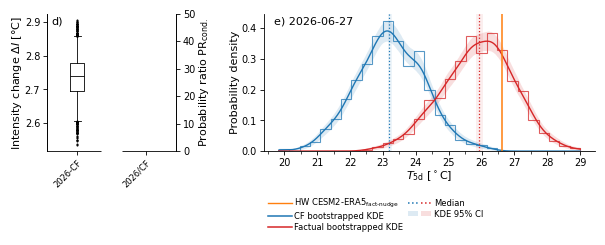

In [9]:
# updated figure: factual vs counterfactual only

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import MultipleLocator
from matplotlib.legend_handler import HandlerTuple
from matplotlib.transforms import blended_transform_factory

display(cf_values.max())

# ---------------------------------------------------------------------
# Publication-ready settings
# ---------------------------------------------------------------------
FIG_WIDTH_MM = 153
FIG_WIDTH_IN = FIG_WIDTH_MM / 25.4

FIG_HEIGHT_IN = FIG_WIDTH_IN * 0.3

FONT_SIZE = 8
SMALL_FONT_SIZE = 7
TINY_FONT_SIZE = 6

plt.rcParams.update({
    "font.size": FONT_SIZE,
    "axes.labelsize": FONT_SIZE,
    "axes.titlesize": FONT_SIZE,
    "xtick.labelsize": SMALL_FONT_SIZE,
    "ytick.labelsize": SMALL_FONT_SIZE,
    "legend.fontsize": TINY_FONT_SIZE,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "axes.linewidth": 0.6,
    "xtick.major.width": 0.6,
    "ytick.major.width": 0.6,
    "xtick.minor.width": 0.5,
    "ytick.minor.width": 0.5,
    "xtick.major.size": 3,
    "ytick.major.size": 3,
    "xtick.minor.size": 1.8,
    "ytick.minor.size": 1.8,
})

# ---------------------------------------------------------------------
# Figure layout
# ---------------------------------------------------------------------
fig = plt.figure(figsize=(FIG_WIDTH_IN, FIG_HEIGHT_IN))

gs = fig.add_gridspec(
    nrows=1,
    ncols=2,
    width_ratios=[0.28, 0.72],
    wspace=0.38,
)

# =====================================================================
# LEFT PANEL: BOXPLOTS (factual vs counterfactual only)
# =====================================================================
ax1 = fig.add_subplot(gs[0, 0])

LW = 0.6

common_boxprops = {
    "widths": 0.16,
    "vert": True,
    "showfliers": True,
    "patch_artist": False,
    "flierprops": {
        "marker": ".",
        "markersize": 2,
        "markeredgewidth": 0.5,
        "markerfacecolor": "black",
        "markeredgecolor": "black",
        "alpha": 0.9,
    },
    "medianprops": {"linewidth": LW, "color": "black"},
    "boxprops": {"linewidth": LW, "color": "black"},
    "whiskerprops": {"linewidth": LW, "color": "black"},
    "capprops": {"linewidth": LW, "color": "black"},
}

# boxplot positions: intensity change (left axis), PR (right axis)
bp_positions = [0.8, 1.6]

# ---------------------------------------------------------------------
# Left axis: intensity change
# ---------------------------------------------------------------------
ax1.boxplot(
    boot_median_diff,
    positions=[bp_positions[0]],
    whis=[2.5, 97.5],
    **common_boxprops,
)

ax1.set_ylabel(
    "Intensity change " + r"$\mathrm{\Delta} I$ [°C]",
    labelpad=0.5,
)

ax1.set_xlim(0.45, 1.95)

ax1.tick_params(
    axis="both",
    which="major",
    direction="out",
    pad=2,
)

# ---------------------------------------------------------------------
# Right y-axis: conditional probability ratio
# ---------------------------------------------------------------------
ax2 = ax1.twinx()

ax2.boxplot(
    pr_boot,
    positions=[bp_positions[1]],
    whis=[2.5, 97.5],
    **common_boxprops,
)

ax2.set_ylabel(
    "Probability ratio " + r"$\mathrm{PR_{cond.}}$",
    labelpad=0.8,
)

ax2.tick_params(
    axis="y",
    which="major",
    direction="out",
    pad=2,
)

ax2.set_ylim(0, 50)
ax2.spines["bottom"].set_visible(False)   # avoid ax2's spine covering the white gap

# ---------------------------------------------------------------------
# Individual x-axis labels
# ---------------------------------------------------------------------
ax1.set_xticks(bp_positions)

ax1.set_xticklabels(
    [
        "2026-CF",
        "2026/CF",
    ],
    fontsize=TINY_FONT_SIZE,
    rotation=45,
    ha="right",
    rotation_mode="anchor",
)

# ---------------------------------------------------------------------
# Interrupt the x-axis line between the two boxes (white gap, no marks)
# ---------------------------------------------------------------------
gap_center = (bp_positions[0] + bp_positions[1]) / 2
gap_halfwidth = 0.12
gap_lo, gap_hi = gap_center - gap_halfwidth, gap_center + gap_halfwidth

# x in data coords, y in axes-fraction coords (0 = bottom spine)
trans = blended_transform_factory(ax1.transData, ax1.transAxes)

ax1.plot(
    [gap_lo, gap_hi], [0, 0],
    transform=trans,
    color="white",
    linewidth=2.5,
    clip_on=False,
    zorder=10,
    solid_capstyle="butt",
)

# ---------------------------------------------------------------------
# Panel label
# ---------------------------------------------------------------------
ax1.text(
    0.03,
    0.98,
    "d)",
    transform=ax1.transAxes,
    fontsize=FONT_SIZE,
    ha="left",
    va="top",
)

# ---------------------------------------------------------------------
# Styling
# ---------------------------------------------------------------------
ax1.spines["top"].set_visible(False)
ax2.spines["top"].set_visible(False)

# =====================================================================
# RIGHT PANEL: DISTRIBUTIONS (factual vs counterfactual only)
# =====================================================================
ax = fig.add_subplot(gs[0, 1])


ax.hist(
    fact_values,
    bins=bins,
    density=True,
    histtype="step",
    linewidth=0.8,
    alpha=0.75,
    color="tab:red",
)

ax.hist(
    cf_values,
    bins=bins,
    density=True,
    histtype="step",
    linewidth=0.8,
    alpha=0.75,
    color="tab:blue",
)

# ---------------------------------------------------------------------
# KDE confidence intervals
# ---------------------------------------------------------------------
ax.fill_between(
    x,
    cf_kde_low,
    cf_kde_high,
    color="tab:blue",
    alpha=0.15,
    linewidth=0,
)

ax.fill_between(
    x,
    fact_kde_low,
    fact_kde_high,
    color="tab:red",
    alpha=0.15,
    linewidth=0,
)

# ---------------------------------------------------------------------
# KDE lines
# ---------------------------------------------------------------------
ax.plot(
    x,
    cf_kde,
    color="tab:blue",
    linewidth=1.0,
)

ax.plot(
    x,
    fact_kde,
    color="tab:red",
    linewidth=1.0,
)

# ---------------------------------------------------------------------
# Median lines
# ---------------------------------------------------------------------
ax.axvline(
    float(cf_boot_median),
    color="tab:blue",
    linestyle=":",
    linewidth=0.9,
)

ax.axvline(
    float(fact_boot_median),
    color="tab:red",
    linestyle=":",
    linewidth=0.9,
)

# ---------------------------------------------------------------------
# Median confidence intervals
# ---------------------------------------------------------------------
ax.axvspan(
    cf_median_ci_low,
    cf_median_ci_high,
    color="tab:blue",
    alpha=0.08,
    linewidth=0,
)

ax.axvspan(
    fact_median_ci_low,
    fact_median_ci_high,
    color="tab:red",
    alpha=0.08,
    linewidth=0,
)

# ---------------------------------------------------------------------
# Truth lines
# ---------------------------------------------------------------------


ax.axvline(
    float(fact_truth_ger.values),
    color="tab:orange",
    linestyle="-",
    linewidth=1.1,
)

# ---------------------------------------------------------------------
# Labels
# ---------------------------------------------------------------------
ax.set_xlabel(
    r"$T_{\mathrm{5d}}$ [$^\circ$C]",
    labelpad=0.5,
)

ax.set_ylabel(
    "Probability density",
    labelpad=1,
)

# ---------------------------------------------------------------------
# Ticks
# ---------------------------------------------------------------------
ax.xaxis.set_major_locator(MultipleLocator(1.0))
ax.xaxis.set_minor_locator(MultipleLocator(0.5))

ax.tick_params(
    axis="both",
    which="major",
    direction="out",
    pad=2,
)

ax.tick_params(
    axis="x",
    which="minor",
    direction="out",
)

# ---------------------------------------------------------------------
# Panel and date labels
# ---------------------------------------------------------------------
ax.text(
    0.03,
    0.98,
    f"e) {DATE}",
    transform=ax.transAxes,
    fontsize=FONT_SIZE,
    ha="left",
    va="top",
)

# ---------------------------------------------------------------------
# Styling
# ---------------------------------------------------------------------
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# ---------------------------------------------------------------------
# Legend (single, two columns)
# ---------------------------------------------------------------------
legend_handles = [
    Line2D([0], [0], color="tab:orange", linestyle="-", linewidth=1),
    (Line2D([0], [0], color="tab:blue", linewidth=1.1),),
    (Line2D([0], [0], color="tab:red", linewidth=1.1),),
    (Line2D([0], [0], color="tab:blue", linewidth=1.1, linestyle=":"),
     Line2D([0], [0], color="tab:red", linewidth=1.1, linestyle=":")),
    (Patch(facecolor="tab:blue", alpha=0.15, edgecolor="none"),
     Patch(facecolor="tab:red", alpha=0.15, edgecolor="none")),
]
legend_labels = [
    r"HW $\mathrm{CESM2\text{-}ERA5_{fact\text{-}nudge}}$",
    "CF bootstrapped KDE",
    "Factual bootstrapped KDE",
    "Median",
    "KDE 95% CI",
]

ax.legend(
    handles=legend_handles,
    labels=legend_labels,
    handler_map={tuple: HandlerTuple(ndivide=None)},
    loc="upper left",
    bbox_to_anchor=(0.0, -0.30),
    frameon=False,
    handlelength=2.8,
    handletextpad=0.35,
    borderaxespad=0.15,
    labelspacing=0.22,
    columnspacing=0.55,
    ncol=2,
    fontsize=TINY_FONT_SIZE,
)

# ---------------------------------------------------------------------
# Final layout
# ---------------------------------------------------------------------
fig.subplots_adjust(
    left=0.075,
    right=0.985,
    bottom=0.20,
    top=0.96,
)

fig.savefig(
     f"{standardization}_Figure04e_extension_updated.pdf",
     bbox_inches="tight",
     pad_inches=0.01,
)

# --------------------------------------------

In [ ]:
# updated figure SI

# Publication-ready settings
FIG_WIDTH_MM = 153
FIG_WIDTH_IN = FIG_WIDTH_MM / 25.4

FIG_HEIGHT_IN = FIG_WIDTH_IN * 0.3

FONT_SIZE = 8
SMALL_FONT_SIZE = 7
TINY_FONT_SIZE = 6

plt.rcParams.update({
    "font.size": FONT_SIZE,
    "axes.labelsize": FONT_SIZE,
    "axes.titlesize": FONT_SIZE,
    "xtick.labelsize": SMALL_FONT_SIZE,
    "ytick.labelsize": SMALL_FONT_SIZE,
    "legend.fontsize": TINY_FONT_SIZE,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "axes.linewidth": 0.6,
    "xtick.major.width": 0.6,
    "ytick.major.width": 0.6,
    "xtick.minor.width": 0.5,
    "ytick.minor.width": 0.5,
    "xtick.major.size": 3,
    "ytick.major.size": 3,
    "xtick.minor.size": 1.8,
    "ytick.minor.size": 1.8,
})

# ---------------------------------------------------------------------
# Figure layout
# ---------------------------------------------------------------------
fig = plt.figure(figsize=(FIG_WIDTH_IN, FIG_HEIGHT_IN))

gs = fig.add_gridspec(
    nrows=1,
    ncols=2,
    width_ratios=[0.28, 0.72],
    wspace=0.38,
)

# =====================================================================
# LEFT PANEL: BLANK (whitespace placeholder — boxplots removed)
# =====================================================================
ax1 = fig.add_subplot(gs[0, 0])
ax1.axis("off")

# =====================================================================
# RIGHT PANEL: DISTRIBUTIONS
# =====================================================================
ax = fig.add_subplot(gs[0, 1])

# ---------------------------------------------------------------------
# Conditional histogram — factual only
# ---------------------------------------------------------------------
ax.hist(
    fact_values,
    bins=bins,
    density=True,
    histtype="step",
    linewidth=0.8,
    alpha=0.75,
    color="tab:red",
)

ax.hist(
    cf_2028_values,
    bins=bins,
    density=True,
    histtype="step",
    linewidth=0.8,
    alpha=0.75,
    color="tab:purple",
)

ax.hist(
    cf_2053_values,
    bins=bins,
    density=True,
    histtype="step",
    linewidth=0.8,
    alpha=0.75,
    color="tab:pink",
)

# ---------------------------------------------------------------------
# KDE confidence intervals — factual, 2028, 2053
# ---------------------------------------------------------------------
ax.fill_between(
    x,
    fact_kde_low,
    fact_kde_high,
    color="tab:red",
    alpha=0.15,
    linewidth=0,
)

ax.fill_between(
    x,
    cf_2028_kde_low,
    cf_2028_kde_high,
    color="tab:purple",
    alpha=0.15,
    linewidth=0,
)

ax.fill_between(
    x,
    cf_2053_kde_low,
    cf_2053_kde_high,
    color="tab:pink",
    alpha=0.15,
    linewidth=0,
)

# ---------------------------------------------------------------------
# KDE lines — factual, 2028, 2053
# ---------------------------------------------------------------------
ax.plot(
    x,
    fact_kde,
    color="tab:red",
    linewidth=1.0,
)

ax.plot(
    x,
    cf_2028_kde,
    color="tab:purple",
    linewidth=1.0,
)

ax.plot(
    x,
    cf_2053_kde,
    color="tab:pink",
    linewidth=1.0,
)

# ---------------------------------------------------------------------
# Curve labels — 2028 and 2053, right tail
# ---------------------------------------------------------------------
#ax.annotate(
#    "2028",
#    xy=(32.8, 0.1),
#    xytext=(0, 3),
#    textcoords="offset points",
#    ha="center",
#    va="bottom",
#    fontsize=TINY_FONT_SIZE,
#    color="tab:purple",
#)

#ax.annotate(
#    "2053",
#    xy=(34.75, 0.05),
#    xytext=(0, 3),
#   textcoords="offset points",
#   ha="center",
#    va="bottom",
#    fontsize=TINY_FONT_SIZE,
#    color="tab:pink",
#)

# ---------------------------------------------------------------------
# Median lines — factual, 2028, 2053
# ---------------------------------------------------------------------
ax.axvline(
    float(fact_boot_median),
    color="tab:red",
    linestyle=":",
    linewidth=0.9,
)

ax.axvline(
    float(cf_2028_boot_median),
    color="tab:purple",
    linestyle=":",
    linewidth=0.9,
)

ax.axvline(
    float(cf_2053_boot_median),
    color="tab:pink",
    linestyle=":",
    linewidth=0.9,
)

# ---------------------------------------------------------------------
# Median confidence intervals — factual, 2028, 2053
# ---------------------------------------------------------------------
ax.axvspan(
    fact_median_ci_low,
    fact_median_ci_high,
    color="tab:red",
    alpha=0.08,
    linewidth=0,
)

ax.axvspan(
    cf_2028_median_ci_low,
    cf_2028_median_ci_high,
    color="tab:purple",
    alpha=0.08,
    linewidth=0,
)

ax.axvspan(
    cf_2053_median_ci_low,
    cf_2053_median_ci_high,
    color="tab:pink",
    alpha=0.08,
    linewidth=0,
)

# ---------------------------------------------------------------------
# Truth line — factual only
# ---------------------------------------------------------------------
ax.axvline(
    float(fact_truth_ger.values),
    color="tab:orange",
    linestyle="-",
    linewidth=1.1,
)

# ---------------------------------------------------------------------
# Labels
# ---------------------------------------------------------------------
ax.set_xlabel(
    r"$\mathrm{T}_{5d}$ [$^\circ$C]",
    labelpad=0.5,
)

ax.set_ylabel(
    "Probability density",
    labelpad=1,
)

# ---------------------------------------------------------------------
# Ticks
# ---------------------------------------------------------------------
ax.xaxis.set_major_locator(MultipleLocator(1.0))
ax.xaxis.set_minor_locator(MultipleLocator(0.5))

ax.tick_params(
    axis="both",
    which="major",
    direction="out",
    pad=2,
)

ax.tick_params(
    axis="x",
    which="minor",
    direction="out",
)

# ---------------------------------------------------------------------
# Panel and date labels
# ---------------------------------------------------------------------
ax.text(
    0.03,
    0.98,
    f"{DATE}",
    transform=ax.transAxes,
    fontsize=FONT_SIZE,
    ha="left",
    va="top",
)

# ---------------------------------------------------------------------
# Styling
# ---------------------------------------------------------------------
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

legend_handles = [
    Line2D(
        [0], [0],
        color="tab:orange",
        linestyle="-",
        linewidth=1,
        label=r"$\mathrm{ETH^{1300}_{fact}}$ on 1997-07-22"
    ),
    (
        Line2D([0], [0], color="tab:red", linewidth=1.1),
    ),
    (
        Line2D([0], [0], color="tab:purple", linewidth=1.1),
    ),
    (
        Line2D([0], [0], color="tab:pink", linewidth=1.1),
    ),
    (
        Line2D([0], [0], color="tab:red", linewidth=1.1, linestyle=":"),
        Line2D([0], [0], color="tab:purple", linewidth=1.1, linestyle=":"),
        Line2D([0], [0], color="tab:pink", linewidth=1.1, linestyle=":"),
    ),
    (
        Patch(facecolor="tab:red", alpha=0.15, edgecolor="none"),
        Patch(facecolor="tab:purple", alpha=0.15, edgecolor="none"),
        Patch(facecolor="tab:pink", alpha=0.15, edgecolor="none"),
    ),
]

legend_labels = [
    r"HW $\mathrm{CESM2\text{-}ERA5_{fact\text{-}nudge}}$",
    "Factual 2003 (histogram and emp. pdf)",
    "2028 (emp. pdf)",
    "2053 (emp. pdf)",
    "Median",
    "KDE 95% CI",
]

ax.legend(
    handles=legend_handles,
    labels=legend_labels,
    handler_map={tuple: HandlerTuple(ndivide=None)},
    loc="upper center",
    bbox_to_anchor=(0.5, -0.25),
    frameon=False,
    handlelength=2.8,
    handletextpad=0.35,
    borderaxespad=0.15,
    labelspacing=0.22,
    columnspacing=0.55,
    ncol=2,
    fontsize=TINY_FONT_SIZE,
)

# ---------------------------------------------------------------------
# Final layout
# ---------------------------------------------------------------------
fig.subplots_adjust(
    left=0.075,
    right=0.985,
    bottom=0.20,
    top=0.96,
)

# ---------------------------------------------------------------------
# Save
# ---------------------------------------------------------------------


#fig.savefig(
#     f"{standardization}_Figure04e_extension_updated.pdf",
#     bbox_inches="tight",
#     pad_inches=0.01,
#)

plt.show()

In [ ]:
print("Heatwave:", fact_truth_ger.values)
print("max T in counterfactual condition. ensemble", cf_values.max())

# model 6037
# ---------------------------------------------------------------------
# Print intensity change statistics
# ---------------------------------------------------------------------
print("\n=== Intensity Change ===")

print("CF:")
print("  Median =", np.median(boot_median_diff))
print("  Mean   =", np.mean(boot_median_diff))
print("  95% CI =", np.percentile(boot_median_diff, [2.5, 97.5]))

print("\n2028:")
print("  Median =", np.median(boot_median_diff_2028))
print("  Mean   =", np.mean(boot_median_diff_2028))
print("  95% CI =", np.percentile(boot_median_diff_2028, [2.5, 97.5]))

print("\n2053:")
print("  Median =", np.median(boot_median_diff_2053))
print("  Mean   =", np.mean(boot_median_diff_2053))
print("  95% CI =", np.percentile(boot_median_diff_2053, [2.5, 97.5]))


# ---------------------------------------------------------------------
# Print PR statistics
# ---------------------------------------------------------------------
print("\n=== Conditional Probability Ratio (PR) ===")

print("CF:")
print("  Median =", np.median(pr_boot))
print("  Mean   =", np.mean(pr_boot))
print("  95% CI =", np.percentile(pr_boot, [2.5, 97.5]))

print("\n2028:")
print("  Median =", np.median(pr_boot_2028))
print("  Mean   =", np.mean(pr_boot_2028))
print("  95% CI =", np.percentile(pr_boot_2028, [2.5, 97.5]))

print("\n2053:")
print("  Median =", np.median(pr_boot_2053))
print("  Mean   =", np.mean(pr_boot_2053))
print("  95% CI =", np.percentile(pr_boot_2053, [2.5, 97.5]))